# 04. Análisis exploratorio y preprocesamiento



## Problemas identificados

Se identificaron cinco problemas que afectan las comparaciones entre elecciones:

| | Problema | Consecuencia si no se arregla |
|---|---|---|
| 1 | Los códigos no tienen el mismo ancho entre años | Un `groupby` entre años parte cada grupo en dos, sin avisar |
| 2 | El texto `NULL` y `N/A` son valores, no vacíos | `pd.read_csv` los vuelve nulos y aparecen datos faltantes donde hay valor |
| 3 | **`cod_puesto` apunta a lugares distintos según el año** | Un panel territorial compararía puestos diferentes y mediría volatilidad falsa |
| 4 | **`cod_candidato` no identifica a un candidato** | La oferta del Concejo daba 17 candidatos en vez de 275 y 359 |
| 5 | La zona 98 parece un consolidado y es la cárcel | Se habría borrado un puesto real con 149 electores |

Los problemas de identificación de puestos y candidaturas afectan los resultados y se verifican en las secciones siguientes.

## Criterios de tratamiento

- No imputa valores faltantes.
- Marca los valores extremos sin eliminarlos.
- Mantiene separadas las unidades de mesa y puesto.
- No infiere comportamientos individuales a partir de datos agregados.

## 0. Preparación

Se configura el estilo de los gráficos y una paleta accesible. Las barras incluyen etiquetas de valor para mantener la legibilidad.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.patheffects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd()
if not (RAIZ / "src").is_dir():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

ANALITICO = RAIZ / "datos" / "analitico"
GEO = RAIZ / "datos" / "geograficos"
FIGURAS = RAIZ / "resultados" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

# ---- Paleta validada (ver docs). Orden fijo, nunca ciclado. ----
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
          "#008300", "#4a3aa7", "#e34948"]
# Para dispersión, mapa y cualquier gráfico donde todos los pares se ven a la vez,
# el máximo validado son TRES colores. Más allá de eso se agrupa en "otros".
PALETA_TODOS_LOS_PARES = PALETA[:3]
SECUENCIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIVERGENTE = ["#0d366b", "#256abf", "#86b6ef", "#f0efec", "#ec835a", "#d03b3b", "#7d1f1f"]
SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
TINTA_3 = "#8a8880"
ESTADO = {"bien": "#0ca30c", "aviso": "#fab219", "grave": "#ec835a", "critico": "#d03b3b"}

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 110, "savefig.dpi": 160,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.labelsize": 10, "axes.labelcolor": TINTA_2,
    "text.color": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#d9d8d2", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#ebeae4", "grid.linewidth": 0.8, "axes.grid": True,
    "axes.grid.axis": "y", "legend.frameon": False, "legend.fontsize": 9,
    "xtick.direction": "out", "ytick.direction": "out",
    "lines.linewidth": 2.0, "lines.markersize": 6,
})


def marco(titulo, subtitulo=None, alto=4.2, ancho=10.0, eje_y_grid=True):
    """Figura con titulo y subtitulo alineados al borde izquierdo del eje.

    Dos detalles que parecen cosmeticos y no lo son. Primero, `ax.grid(axis=...)`
    **enciende** una rejilla pero no apaga la otra: sin el `grid(False)` previo, la
    rejilla horizontal de los rcParams sigue encendida y en un grafico de barras
    horizontales dibuja lineas que atraviesan las barras. Segundo, el titulo va anclado
    al eje y no a la figura, para que titulo y subtitulo empiecen en la misma columna
    sea cual sea el ancho de las etiquetas del eje y.
    """
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.grid(False)
    ax.grid(True, axis="y" if eje_y_grid else "x")
    ax.set_axisbelow(True)
    desplazamiento = 1.14 if subtitulo else 1.04
    ax.text(0, desplazamiento, titulo, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=12.5, fontweight="semibold", color=TINTA)
    if subtitulo:
        ax.set_title(subtitulo, loc="left", fontsize=9.5, color=TINTA_2,
                     fontweight="normal", pad=8)
    return fig, ax


def etiquetar_barras_h(ax, barras, valores, fmt="{:,.0f}", dentro_si_grande=True):
    """Etiqueta cada barra horizontal. Es la 'regla de relieve': varios colores de la
    paleta no llegan a 3:1 de contraste, asi que el valor va escrito."""
    lim = ax.get_xlim()[1]
    for b, v in zip(barras, valores):
        if pd.isna(v):
            continue
        ancho = b.get_width()
        fuera = ancho < lim * 0.35 or not dentro_si_grande
        ax.text(ancho + lim * 0.012 if fuera else ancho - lim * 0.012,
                b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", ha="left" if fuera else "right",
                fontsize=8.5, color=TINTA_2 if fuera else "white", zorder=6,
                # Halo: sin el, una linea de referencia que cruce la barra parte el
                # numero por la mitad y deja de leerse.
                path_effects=[mpl.patheffects.withStroke(
                    linewidth=2.2,
                    foreground=SUPERFICIE if fuera else b.get_facecolor())])


def etiquetar_barras_v(ax, barras, valores, fmt="{:,.1f}"):
    for b, v in zip(barras, valores):
        if pd.isna(v):
            continue
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v),
                ha="center", va="bottom", fontsize=8.5, color=TINTA_2)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")
    return fig


def leer(nombre, **kw):
    return pd.read_csv(ANALITICO / nombre, keep_default_na=False,
                       na_values=[""], **kw)


print("raíz del proyecto:", RAIZ)
print("matplotlib", mpl.__version__, "| pandas", pd.__version__)
print("datasets analíticos disponibles:",
      len(list(ANALITICO.glob("*.csv"))) if ANALITICO.is_dir() else 0)

raíz del proyecto: d:\Users\LAURA PEREZ\Desktop\CIENCIA DE DATOS\Proy_Electoral_Bca
matplotlib 3.11.2 | pandas 3.0.6
datasets analíticos disponibles: 23


### 0.1. Reconstrucción de datasets (opcional)

La celda reconstruye los datasets en `datos/analitico/` a partir de `datos/procesados/`. No modifica `datos/brutos/`. Omítela si los datos no han cambiado.

In [2]:
RECONSTRUIR = False  # pon True para rehacer los datasets desde datos/procesados/

if RECONSTRUIR:
    import subprocess
    r = subprocess.run([sys.executable, "-u",
                        str(RAIZ / "src" / "transformacion" / "construir_datasets.py")],
                       capture_output=True, text=True, cwd=str(RAIZ))
    print(r.stdout[-4000:])
    if r.returncode != 0:
        print("--- errores ---")
        print(r.stderr[-3000:])
else:
    print("Se usan los datasets ya construidos en datos/analitico/.")
    inv = leer("inventario_datasets.csv")
    print(inv.to_string(index=False))

Se usan los datasets ya construidos en datos/analitico/.
                                                  dataset                          archivo  filas  columnas
             voto por mesa y opción, todas las elecciones                   votos_mesa.csv 302979        25
                  TABLA PRINCIPAL: un puesto por elección              puesto_eleccion.csv    770        70
                   identidad estable de puesto entre años                panel_puestos.csv    190        14
                        totales del distrito por elección            agregado_eleccion.csv     12        25
                       totales por comuna y corregimiento          agregado_territorio.csv    164        18
                         votos de cada lista por elección             partido_eleccion.csv    226        11
                        HHI y número efectivo de partidos       concentracion_eleccion.csv     12         9
                      índice de Pedersen entre elecciones                  vola

In [40]:
from html import escape
from IPython.display import HTML, Markdown, display

display(Markdown("## Composición de los datasets analíticos\n\nResumen de cada archivo de `datos/analitico/`. Abre cada dataset para consultar sus columnas, tipo inferido, faltantes, valores distintos y ejemplos."))

inventario = leer('inventario_datasets.csv')
descripcion = dict(zip(inventario['archivo'], inventario['dataset']))
archivos = [p for p in ANALITICO.glob('*.csv') if p.name != 'inventario_datasets.csv']
orden = {nombre: i for i, nombre in enumerate(descripcion)}
archivos.sort(key=lambda p: (orden.get(p.name, len(orden)), p.name))

resumen_datasets = []
detalles_datasets = []
for ruta in archivos:
    opciones = {'keep_default_na': False, 'na_values': ['']}
    if ruta.name == 'votos_mesa.csv':
        opciones['dtype'] = {
            'anio': str, 'cod_zona': str, 'cod_puesto': str,
            'cod_comuna': str, 'mesa': str, 'cod_partido': str,
            'cod_candidato': str, 'cod_corporacion': str,
        }
    datos = pd.read_csv(ruta, **opciones)
    if ruta.name == 'votos_mesa.csv' and 'votos' in datos:
        datos['votos'] = pd.to_numeric(datos['votos'], errors='coerce')

    resumen_datasets.append({
        'Dataset': descripcion.get(ruta.name, ruta.stem.replace('_', ' ')),
        'Archivo': ruta.name,
        'Filas': len(datos),
        'Columnas': len(datos.columns),
    })
    esquema = []
    for columna in datos.columns:
        serie = datos[columna]
        ejemplos = serie.dropna().astype(str).drop_duplicates().head(3).tolist()
        ejemplos = [valor if len(valor) <= 45 else valor[:42] + '...' for valor in ejemplos]
        esquema.append({
            'Columna': columna,
            'Tipo': str(serie.dtype),
            'Faltantes': int(serie.isna().sum()),
            '% faltantes': round(100 * serie.isna().mean(), 1),
            'Valores distintos': int(serie.nunique(dropna=True)),
            'Ejemplos': ' · '.join(ejemplos),
        })
    tabla = pd.DataFrame(esquema).to_html(index=False, escape=True, border=0)
    nombre = descripcion.get(ruta.name, ruta.stem.replace('_', ' '))
    detalles_datasets.append(
        f'<details><summary><strong>{escape(nombre)}</strong> — {len(datos):,} filas · '
        f'{len(datos.columns)} columnas ({escape(ruta.name)})</summary>{tabla}</details>'
    )
    del datos

display(pd.DataFrame(resumen_datasets))
display(HTML('<style>details{margin:.45em 0;padding:.55em;border:1px solid #ddd;border-radius:5px}'
             'summary{cursor:pointer}details table{font-size:.9em;margin-top:.6em}'
             'details th,details td{padding:.3em .55em;text-align:left;border-bottom:1px solid #eee}'
             '</style>' + ''.join(detalles_datasets)))

## Composición de los datasets analíticos

Resumen de cada archivo de `datos/analitico/`. Abre cada dataset para consultar sus columnas, tipo inferido, faltantes, valores distintos y ejemplos.

,Dataset,Archivo,Filas,Columnas
0,"voto por mesa y opción, todas las elecciones",votos_mesa.csv,302979,25
1,TABLA PRINCIPAL: un puesto por elección,puesto_eleccion.csv,770,70
2,identidad estable de puesto entre años,panel_puestos.csv,190,14
3,totales del distrito por elección,agregado_eleccion.csv,12,25
4,totales por comuna y corregimiento,agregado_territorio.csv,164,18
5,votos de cada lista por elección,partido_eleccion.csv,226,11
6,HHI y número efectivo de partidos,concentracion_eleccion.csv,12,9
7,índice de Pedersen entre elecciones,volatilidad.csv,5,9
8,listas y candidatos que compitieron,oferta_electoral.csv,12,9
9,votos de cada candidatura,candidato_eleccion.csv,2583,11


Columna,Tipo,Faltantes,% faltantes,Valores distintos,Ejemplos
anio,str,0,0.0,3,2019 · 2022 · 2023
familia,str,0,0.0,2,territorial · congreso
corporacion,str,0,0.0,7,ALCALDE · ASAMBLEA · CONCEJO
cod_corporacion,str,0,0.0,5,003 · 002 · 004
es_uninominal,bool,0,0.0,2,True · False
cod_circunscripcion,int64,0,0.0,5,2 · 1 · 3
cod_zona,str,0,0.0,9,01 · 02 · 03
cod_puesto,str,0,0.0,20,01 · 02 · 03
puesto,str,0,0.0,87,COL JHON.F. KENNEDY - F · COL JOSE PRUDENCIO PADILLA - D · COL JHON. F. KENNEDY - D
id_puesto,str,0,0.0,107,17c3908765d0 · 364cb419e834 · e9dce808416f


# Parte 1. Cobertura de datos
Elecciones disponibles, nivel de detalle y faltantes.

In [3]:
larga = leer("votos_mesa.csv", dtype={"anio": str, "cod_zona": str,
                                      "cod_puesto": str, "cod_comuna": str,
                                      "mesa": str, "cod_partido": str,
                                      "cod_candidato": str,
                                      "cod_corporacion": str})
larga["votos"] = pd.to_numeric(larga["votos"], errors="coerce")

inf_unif = leer("informe_unificacion.csv")
print("TABLA LARGA: %d filas · %d columnas" % larga.shape)
print("\nElecciones leídas:")
print(inf_unif[["eleccion", "filas", "puestos", "mesas", "votos"]].to_string(index=False))
print("\nTotal de votos en el corpus: {:,}".format(int(larga["votos"].sum())))

TABLA LARGA: 302979 filas · 25 columnas

Elecciones leídas:
       eleccion  filas  puestos  mesas  votos
   2019_ALCALDE   4418       63    525 121980
  2019_ASAMBLEA  33473       63    525 119968
   2019_CONCEJO  51457       63    525 121765
2019_GOBERNADOR   4524       63    525 120891
       2019_JAL  22758       62    534 116070
    2022_CAMARA  20862       61    547 100605
    2022_SENADO  27345       61    546 101430
   2023_ALCALDE   6109       67    593 132133
  2023_ASAMBLEA  35191       67    593 128983
   2023_CONCEJO  61400       67    593 131961
2023_GOBERNADOR   6369       67    593 129197
       2023_JAL  29073       66    592 127484

Total de votos en el corpus: 1,452,467


### 1.1. Cobertura

El corpus incluye tres procesos electorales con datos por mesa. La Registraduría no publicó archivos abiertos con ese nivel de detalle antes de 2018. Los procesos de 2026 aún no tienen resultados.

In [4]:
cob = pd.DataFrame([
    {"proceso": "Territoriales 2019", "anio": "2019", "nivel": "mesa",
     "corporaciones": "Alcalde, Concejo, Asamblea, Gobernador, JAL", "estado": "completo"},
    {"proceso": "Congreso 2022", "anio": "2022", "nivel": "mesa",
     "corporaciones": "Senado, Cámara", "estado": "completo"},
    {"proceso": "Territoriales 2023", "anio": "2023", "nivel": "mesa",
     "corporaciones": "Alcalde, Concejo, Asamblea, Gobernador, JAL", "estado": "completo"},
    {"proceso": "Presidencia 2018 y 2022", "anio": "2018, 2022", "nivel": "—",
     "corporaciones": "Presidencia", "estado": "NO ingestado (censo sí está)"},
    {"proceso": "Territoriales 2000–2015", "anio": "2000–2015", "nivel": "—",
     "corporaciones": "—", "estado": "NO hay datos abiertos (instaladores .exe)"},
    {"proceso": "Serie histórica CEDE", "anio": "1972–2023", "nivel": "municipio",
     "corporaciones": "todas", "estado": "PENDIENTE de descarga"},
    {"proceso": "Candidaturas inscritas", "anio": "—", "nivel": "candidato",
     "corporaciones": "—", "estado": "PENDIENTE, sin ruta automática"},
    {"proceso": "Financiación CNE", "anio": "2023", "nivel": "candidato",
     "corporaciones": "Concejo", "estado": "DESCARTADO: cobertura 1,1 %"},
])
print(cob.to_string(index=False))

censo_rutas = sorted((RAIZ / "datos" / "procesados" / "censo").glob("censo_2*.csv"))
print("\nCenso electoral por puesto disponible para:",
      ", ".join(r.stem.split("_")[1] for r in censo_rutas))

                proceso       anio     nivel                               corporaciones                                    estado
     Territoriales 2019       2019      mesa Alcalde, Concejo, Asamblea, Gobernador, JAL                                  completo
          Congreso 2022       2022      mesa                              Senado, Cámara                                  completo
     Territoriales 2023       2023      mesa Alcalde, Concejo, Asamblea, Gobernador, JAL                                  completo
Presidencia 2018 y 2022 2018, 2022         —                                 Presidencia              NO ingestado (censo sí está)
Territoriales 2000–2015  2000–2015         —                                           — NO hay datos abiertos (instaladores .exe)
   Serie histórica CEDE  1972–2023 municipio                                       todas                     PENDIENTE de descarga
 Candidaturas inscritas          — candidato                                       

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


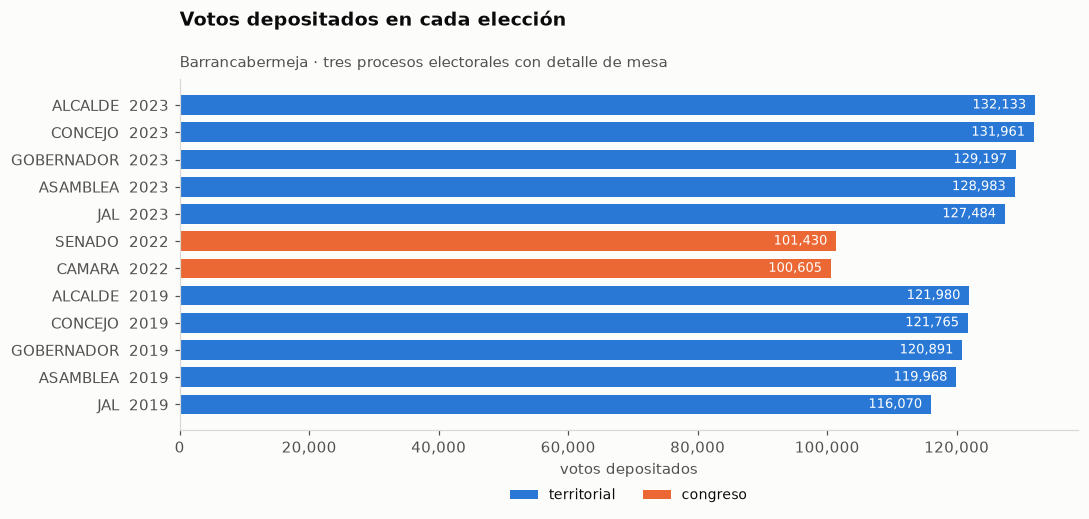

In [5]:
agg = leer("agregado_eleccion.csv")
agg["etiqueta"] = agg["corporacion"] + "  " + agg["anio"].astype(str)
agg = agg.sort_values(["anio", "votos_depositados"])

colores = [PALETA[0] if f == "territorial" else PALETA[1] for f in agg["familia"]]
fig, ax = marco("Votos depositados en cada elección",
                "Barrancabermeja · tres procesos electorales con detalle de mesa",
                alto=5.0, eje_y_grid=False)
ax.grid(axis="x")
b = ax.barh(agg["etiqueta"], agg["votos_depositados"], color=colores, height=0.72)
etiquetar_barras_h(ax, b, agg["votos_depositados"].values)
ax.set_xlabel("votos depositados")
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="territorial"),
                   Patch(facecolor=PALETA[1], label="congreso")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
guardar(fig, "01_votos_por_eleccion")
plt.show()

Las elecciones territoriales registran entre 116 000 y 132 000 votos; las de Congreso 2022, cerca de 100 000. La comparación de participación se presenta en la parte 4.

# Parte 2. Calidad de los datos

Se documentan los cinco problemas identificados y sus efectos en el análisis.

## 2.1. Ancho de los códigos

En Congreso 2022, `cod_candidato` tiene tres dígitos; en las elecciones territoriales, cinco. Por ejemplo, el voto en blanco aparece como `996` y `00996`. Se normaliza el ancho antes de comparar años.

In [6]:
bruto = {}
for r in sorted((RAIZ / "datos" / "procesados" / "votos").rglob("*.csv")):
    d = pd.read_csv(r, dtype=str, keep_default_na=False, na_values=[""])
    bruto["%s_%s" % (d["anio"].iloc[0], d["corporacion"].iloc[0])] = d

cols = ["cod_zona", "cod_puesto", "mesa", "cod_corporacion", "cod_partido",
        "cod_candidato", "cod_circunscripcion", "cod_comuna"]
filas = []
for k, d in sorted(bruto.items()):
    f = {"eleccion": k}
    for c in cols:
        f[c] = "/".join(str(x) for x in sorted({len(str(v))
                                                for v in d[c].dropna()})) if c in d.columns else "-"
    filas.append(f)
anchos = pd.DataFrame(filas)
print("ANCHO DE CADA CÓDIGO, ANTES DE NORMALIZAR (número de caracteres)")
print(anchos.to_string(index=False))

print("\nColumnas donde el ancho NO es el mismo en todas las elecciones:")
for c in cols:
    vistos = set(anchos[c]) - {"-"}
    if len(vistos) > 1:
        print("   %-22s %s" % (c, sorted(vistos)))

ANCHO DE CADA CÓDIGO, ANTES DE NORMALIZAR (número de caracteres)
       eleccion cod_zona cod_puesto mesa cod_corporacion cod_partido cod_candidato cod_circunscripcion cod_comuna
   2019_ALCALDE        2          2  1/2               3           5             5                   1          2
  2019_ASAMBLEA        2          2  1/2               3           5             5                   1          2
   2019_CONCEJO        2          2  1/2               3           5             5                   1          2
2019_GOBERNADOR        2          2  1/2               3           5             5                   1          2
       2019_JAL        2          2  1/2               3           5             5                   1          2
    2022_CAMARA        2          2    4               2           4             3                   2          2
    2022_SENADO        2          2    4               2           4             3                   2          2
   2023_ALCALDE        

In [7]:
print("EL CASO CONCRETO: el voto en blanco")
for k in ("2022_SENADO", "2023_CONCEJO"):
    d = bruto[k]
    e = d[d["clase_opcion"] == "opcion_especial"]
    pares = sorted({(a, b) for a, b in zip(e["cod_candidato"], e["candidato"])})
    print("   %-16s %s" % (k, pares))

print("\nDespués de normalizar, en la tabla larga:")
esp = larga[larga["tipo_opcion"].isin(["blanco", "nulo", "no_marcado"])]
print(esp.groupby(["cod_candidato", "tipo_opcion"]).size().to_string())

EL CASO CONCRETO: el voto en blanco
   2022_SENADO      [('996', 'VOTOS EN BLANCO'), ('997', 'VOTOS NULOS'), ('998', 'VOTOS NO MARCADOS')]
   2023_CONCEJO     [('00996', 'VOTOS EN BLANCO'), ('00997', 'VOTOS NULOS'), ('00998', 'VOTOS NO MARCADOS')]

Después de normalizar, en la tabla larga:
cod_candidato  tipo_opcion
00996          blanco         6971
00997          nulo           6600
00998          no_marcado     6172


## 2.2. Valores de texto que representan faltantes

Las tablas de 2019 usan `NULL` y las de 2022 `N/A` en la columna de comuna. En 2022 también aparece `N/A` en partido para votos en blanco y nulos.

La lectura usa `keep_default_na=False` para conservar esos valores. Su conversión a faltantes se realiza por separado y queda registrada.

In [8]:
print("TEXTO CENTINELA ENCONTRADO Y CONVERTIDO A NULO EXPLÍCITAMENTE")
cen = inf_unif[inf_unif["texto_centinela"].fillna("") != ""][
    ["eleccion", "texto_centinela"]]
for _, r in cen.iterrows():
    print("   %-18s %s" % (r["eleccion"], r["texto_centinela"]))

print("\nDEMOSTRACIÓN del efecto de leer con las opciones por omisión:")
ruta = RAIZ / "datos" / "procesados" / "votos" / "territorial" / "2019" / "reg_2019_terr_concejo.csv"
por_omision = pd.read_csv(ruta, dtype=str)
explicito = pd.read_csv(ruta, dtype=str, keep_default_na=False, na_values=[""])
cmp = pd.DataFrame({
    "columna": ["comuna", "partido"],
    "nulos_leyendo_por_omision": [int(por_omision[c].isna().sum()) for c in ("comuna", "partido")],
    "nulos_leyendo_explicito": [int(explicito[c].isna().sum()) for c in ("comuna", "partido")],
})
cmp["diferencia"] = cmp["nulos_leyendo_por_omision"] - cmp["nulos_leyendo_explicito"]
print(cmp.to_string(index=False))
print("\nEsas %d filas no estaban vacías: decían NULL o N/A." % int(cmp["diferencia"].sum()))

TEXTO CENTINELA ENCONTRADO Y CONVERTIDO A NULO EXPLÍCITAMENTE
   2019_ALCALDE       comuna=NULL(8); partido=N/A(1434); comuna_normalizada=NULL(8)
   2019_ASAMBLEA      comuna=NULL(44); partido=N/A(1552); comuna_normalizada=NULL(44)
   2019_CONCEJO       comuna=NULL(52); partido=N/A(1485); comuna_normalizada=NULL(52)
   2019_GOBERNADOR    comuna=NULL(8); partido=N/A(1532); comuna_normalizada=NULL(8)
   2019_JAL           partido=N/A(1585)
   2022_CAMARA        comuna=N/A(24); partido=N/A(1962); comuna_normalizada=N/A(24)
   2022_SENADO        comuna=N/A(22); partido=N/A(1682); comuna_normalizada=N/A(22)

DEMOSTRACIÓN del efecto de leer con las opciones por omisión:
columna  nulos_leyendo_por_omision  nulos_leyendo_explicito  diferencia
 comuna                         52                        0          52
partido                       1485                        0        1485

Esas 1537 filas no estaban vacías: decían NULL o N/A.


## 2.3. Identificación de puestos

Entre 2019 y 2023 se renumeraron puestos. La combinación `(zona, cod_puesto)` no identifica necesariamente el mismo lugar y no basta para comparar años. La verificación se realizó por tres métodos.

In [9]:
a19 = bruto["2019_CONCEJO"].drop_duplicates(["cod_zona", "cod_puesto"])[
    ["cod_zona", "cod_puesto", "puesto"]].reset_index(drop=True)
a23 = bruto["2023_CONCEJO"].drop_duplicates(["cod_zona", "cod_puesto"])[
    ["cod_zona", "cod_puesto", "puesto"]].reset_index(drop=True)
j = a19.merge(a23, on=["cod_zona", "cod_puesto"], suffixes=("_2019", "_2023"))
dif = j[j["puesto_2019"] != j["puesto_2023"]]

print("PRUEBA 1 · el mismo código, dos lugares")
print("pares (zona, cod_puesto) presentes en 2019 y 2023: %d" % len(j))
print("de esos, con nombre distinto: %d\n" % len(dif))
print(dif.head(12).to_string(index=False))

PRUEBA 1 · el mismo código, dos lugares
pares (zona, cod_puesto) presentes en 2019 y 2023: 61
de esos, con nombre distinto: 26

cod_zona cod_puesto                             puesto_2019                             puesto_2023
      01         04                       COL. INTECOBA - D                INSTITUTO ANTONIO NARIÑO
      01         07                        COL INTECOBA - C                      COL SANTA TERESITA
      01         08                      COL SANTA TERESITA INST. TEC. SUPERIOR INDUSTRIAL - SEDE C
      01         09 INST. TEC. SUPERIOR INDUSTRIAL - SEDE C                    COL. DE LAS AMERICAS
      02         05                      COL ANTONIA SANTOS            INST TEC SUPERIOR INDUSTRIAL
      02         06            INST TEC SUPERIOR INDUSTRIAL              COL LICEO NUEVA GENERACION
      02         07              COL LICEO NUEVA GENERACION  INSTITUTO TECNICO SUPERIOR DE COMERCIO
      03         02          COL DIEGO HDEZ DE GALLEGO SEDE             

In [10]:
from src.transformacion import preparacion as prep

print("PRUEBA 2 · ¿dónde quedó en 2023 el puesto que en 2019 tenía ese código?")
print("(se busca el nombre de 2019 en TODA la tabla de 2023)\n")
hallados = []
for _, r in dif.iterrows():
    mejor, puntaje = None, 0.0
    for _, q in a23.iterrows():
        s = prep.similitud(r["puesto_2019"], q["puesto"])
        if s > puntaje:
            mejor, puntaje = q, s
    if puntaje >= 0.6 and (mejor["cod_zona"], mejor["cod_puesto"]) != (
            r["cod_zona"], r["cod_puesto"]):
        hallados.append({
            "puesto_2019": r["puesto_2019"][:34],
            "codigo_2019": "z%s p%s" % (r["cod_zona"], r["cod_puesto"]),
            "en_2023_esta_en": "z%s p%s" % (mejor["cod_zona"], mejor["cod_puesto"]),
            "con_el_nombre": mejor["puesto"][:32],
            "similitud": round(puntaje, 2)})
reub = pd.DataFrame(hallados)
print(reub.to_string(index=False))
print("\n%d de %d puestos con nombre distinto están demostrablemente REUBICADOS:"
      % (len(reub), len(dif)))
print("su nombre de 2019 aparece en 2023 bajo otro código.")

PRUEBA 2 · ¿dónde quedó en 2023 el puesto que en 2019 tenía ese código?
(se busca el nombre de 2019 en TODA la tabla de 2023)

                       puesto_2019 codigo_2019 en_2023_esta_en                    con_el_nombre  similitud
                 COL. INTECOBA - D     z01 p04         z01 p05                     COL INTECOBA        1.0
                  COL INTECOBA - C     z01 p07         z01 p05                     COL INTECOBA        1.0
                COL SANTA TERESITA     z01 p08         z01 p07               COL SANTA TERESITA        1.0
INST. TEC. SUPERIOR INDUSTRIAL - S     z01 p09         z01 p08 INST. TEC. SUPERIOR INDUSTRIAL -        1.0
      INST TEC SUPERIOR INDUSTRIAL     z02 p06         z01 p08 INST. TEC. SUPERIOR INDUSTRIAL -        1.0
        COL LICEO NUEVA GENERACION     z02 p07         z02 p06       COL LICEO NUEVA GENERACION        1.0
    COL DIEGO HDEZ DE GALLEGO SEDE     z03 p02         z03 p11 COL DIEGO HDEZ DE GALLEGO SEDE B        1.0
        COL TEC D

In [11]:
print("PRUEBA 3 · el censo electoral lo corrobora, y es OTRA fuente")
print("Si el código fuera estable, el potencial electoral de un mismo puesto")
print("debería cambiar poco entre 2019 y 2023.\n")

c19 = pd.read_csv(RAIZ / "datos/procesados/censo/censo_2019_barrancabermeja.csv",
                  dtype=str, keep_default_na=False, na_values=[""])
c23 = pd.read_csv(RAIZ / "datos/procesados/censo/censo_2023_barrancabermeja.csv",
                  dtype=str, keep_default_na=False, na_values=[""])
for c in (c19, c23):
    c["pot"] = pd.to_numeric(c["potencial_electoral"])
m = c19.merge(c23, on=["zona", "cod_puesto"], suffixes=("_19", "_23"))
m["cambio_pct"] = (m["pot_23"] - m["pot_19"]) / m["pot_19"] * 100
m["grupo"] = np.where(m["puesto_votacion_19"] == m["puesto_votacion_23"],
                      "el nombre coincide", "el nombre difiere")

res = m.groupby("grupo")["cambio_pct"].agg(["count", "median", "min", "max"]).round(1)
print(res.to_string())
print("\nDonde el nombre coincide el potencial casi no se mueve (mediana %.1f %%)."
      % res.loc["el nombre coincide", "median"])
print("Donde difiere, se mueve mucho (mediana %.1f %%, extremos %.0f %% y %.0f %%):"
      % (res.loc["el nombre difiere", "median"], res.loc["el nombre difiere", "min"],
         res.loc["el nombre difiere", "max"]))
print("son lugares distintos.")

PRUEBA 3 · el censo electoral lo corrobora, y es OTRA fuente
Si el código fuera estable, el potencial electoral de un mismo puesto
debería cambiar poco entre 2019 y 2023.

                    count  median   min    max
grupo                                         
el nombre coincide     35     0.6 -24.4  242.9
el nombre difiere      26    17.1 -86.6  847.2

Donde el nombre coincide el potencial casi no se mueve (mediana 0.6 %).
Donde difiere, se mueve mucho (mediana 17.1 %, extremos -87 % y 847 %):
son lugares distintos.


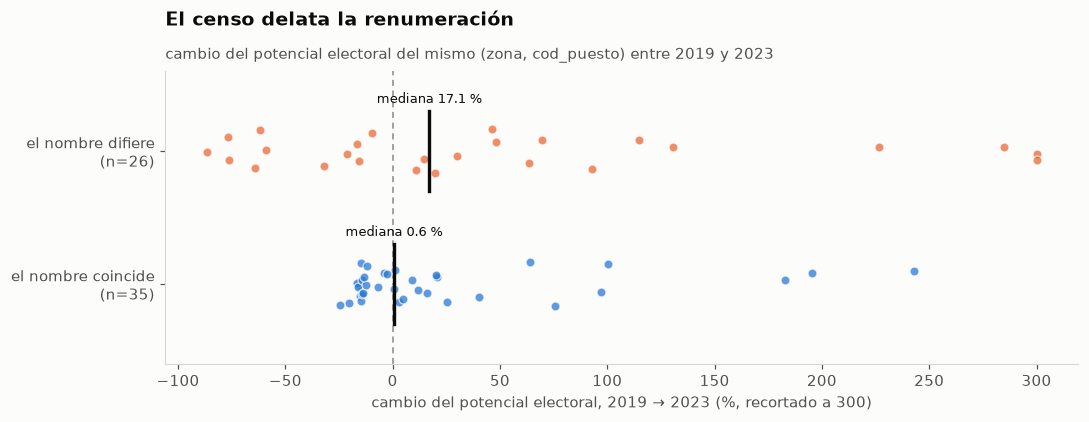

In [12]:
fig, ax = marco("El censo delata la renumeración",
                "cambio del potencial electoral del mismo (zona, cod_puesto) entre 2019 y 2023",
                alto=4.0, eje_y_grid=False)
ax.grid(axis="x")
grupos = ["el nombre coincide", "el nombre difiere"]
for i, (g, col) in enumerate(zip(grupos, PALETA_TODOS_LOS_PARES[:2])):
    v = m.loc[m["grupo"] == g, "cambio_pct"].clip(-100, 300)
    y = np.full(len(v), i) + np.random.default_rng(3).uniform(-0.17, 0.17, len(v))
    ax.scatter(v, y, s=34, color=col, alpha=0.75, edgecolor=SUPERFICIE, linewidth=0.8,
               zorder=3)
    med = m.loc[m["grupo"] == g, "cambio_pct"].median()
    ax.plot([med, med], [i - 0.3, i + 0.3], color=TINTA, lw=2.2, zorder=4)
    ax.text(med, i + 0.36, "mediana %.1f %%" % med, ha="center", fontsize=8.5,
            color=TINTA)
ax.axvline(0, color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
ax.set_yticks(range(len(grupos)))
ax.set_yticklabels(["%s\n(n=%d)" % (g, int((m["grupo"] == g).sum())) for g in grupos])
ax.set_xlabel("cambio del potencial electoral, 2019 → 2023 (%, recortado a 300)")
ax.set_ylim(-0.6, 1.6)
guardar(fig, "02_renumeracion_puestos")
plt.show()

La zona se mantiene entre años, pero no el código de puesto. El panel empareja nombres dentro de cada zona; los puestos sin correspondencia quedan identificados como tales. La evidencia está en `datos/analitico/codigos_de_puesto_reusados.csv`.

## 2.4. Identificación de candidaturas

`cod_candidato` indica el orden de la candidatura dentro de una lista. El mismo código puede corresponder a personas distintas en listas diferentes.

El conteo de candidaturas debe usar también el código de partido. Agrupar solo por `cod_candidato` combina las listas.

In [13]:
print("CUÁNTOS CANDIDATOS AL CONCEJO HAY, DE VERDAD\n")
filas = []
for anio in ("2019", "2023"):
    c = larga[(larga["anio"] == anio) & (larga["corporacion"] == "CONCEJO")
              & (larga["tipo_opcion"] == "candidato")]
    filas.append({
        "anio": anio,
        "contando_solo_cod_candidato": c["cod_candidato"].nunique(),
        "contando_el_par_lista_y_orden": len(c.drop_duplicates(["cod_partido",
                                                                "cod_candidato"])),
        "nombres_distintos": c["nombre_candidato"].nunique(),
    })
print(pd.DataFrame(filas).to_string(index=False))
print("\nEl conteo correcto coincide con los nombres distintos, que es la comprobación")
print("independiente: 275 candidaturas en 2019 y 359 en 2023.")

print("\nEjemplo del choque: el código 00001 en 2023")
ej = larga[(larga["anio"] == "2023") & (larga["corporacion"] == "CONCEJO")
           & (larga["cod_candidato"] == "00001")
           & (larga["tipo_opcion"] == "candidato")]
print(ej.drop_duplicates(["cod_partido"])[
    ["cod_partido", "nombre_partido", "cod_candidato", "nombre_candidato"]
].head(6).to_string(index=False))

CUÁNTOS CANDIDATOS AL CONCEJO HAY, DE VERDAD

anio  contando_solo_cod_candidato  contando_el_par_lista_y_orden  nombres_distintos
2019                           17                            275                275
2023                           17                            359                359

El conteo correcto coincide con los nombres distintos, que es la comprobación
independiente: 275 candidaturas en 2019 y 359 en 2023.

Ejemplo del choque: el código 00001 en 2023
cod_partido                                  nombre_partido cod_candidato                nombre_candidato
      00012 MOVIMIENTO ALTERNATIVO INDÍGENA Y SOCIAL "MAIS"         00001       JHON BLERT CORENA AHUMADA
      00024                    PARTIDO DEMÓCRATA COLOMBIANO         00001 CRISTIAN DAVID CORTEZ CONTRERAS
      00026            PARTIDO POLÍTICO LA FUERZA DE LA PAZ         00001           ALEIDA NOGUERA PUERTO
      00028                   AGRUPACIÓN POLÍTICA EN MARCHA         00001           NORELVIS DIAZ A

## 2.5. Zona 98

La zona 98 tiene `cod_comuna = '00'`. La comuna aparece como `NULL` en 2019, `N/A` en 2022 y `NACIONAL` en 2023.

Corresponde a un puesto de votación de la cárcel, con 149 electores censados y entre 56 y 109 votos. La zona 99 agrupa puestos rurales.

In [14]:
print("QUÉ SON LAS ZONAS 98 Y 99\n")
for k in ("2019_CONCEJO", "2022_SENADO", "2023_CONCEJO"):
    d = bruto[k]
    print(k)
    for z in ("98", "99"):
        s = d[d["cod_zona"] == z]
        if not len(s):
            continue
        print("   zona %s · %d puesto(s) · comuna=%s" % (
            z, s["id_puesto"].nunique(),
            sorted(set(s["cod_comuna"].fillna("(vacío)")))))
        print("            %s" % sorted(set(s["puesto"]))[:4])
    cero = d[d["cod_comuna"] == "00"]
    if len(cero):
        print("   cod_comuna='00' · etiqueta en la fuente: %s · votos: %d"
              % (sorted(set(cero["comuna"].fillna("(vacío)"))),
                 int(pd.to_numeric(cero["votos"]).sum())))
    print()

print("Y en Congreso 2022, seis puestos rurales llegaron SIN cod_comuna:")
s22 = bruto["2022_SENADO"]
sin = s22[s22["cod_comuna"].isna()]
print("   zonas:", sorted(set(sin["cod_zona"])), "· puestos:", sin["id_puesto"].nunique())
print("  ", sorted(set(sin["puesto"]))[:6])
print("\nDe la zona 99 se puede afirmar el ÁMBITO rural con certeza, sin inventar")
print("cuál corregimiento: el territorio queda vacío y el ámbito queda lleno.")

QUÉ SON LAS ZONAS 98 Y 99

2019_CONCEJO
   zona 98 · 1 puesto(s) · comuna=['00']
            ['CARCEL']
   zona 99 · 9 puesto(s) · comuna=['08', '09', '10', '11', '12', '13']
            ['COL BLANCA DURAN DE PADILLA SEDE A', 'COL BLANCA DURAN DE PADILLA SEDE B', 'COL. SAN RAFAEL DE CHUCURI', 'EL LLANITO']
   cod_comuna='00' · etiqueta en la fuente: ['NULL'] · votos: 109

2022_SENADO
   zona 98 · 1 puesto(s) · comuna=['00']
            ['CARCEL']
   zona 99 · 10 puesto(s) · comuna=['(vacío)', '10', '11', '12', '13']
            ['COL BLANCA DURAN DE PADILLA SEDE A', 'COL BLANCA DURAN DE PADILLA SEDE B', 'COL. SAN RAFAEL DE CHUCURI', 'EL LLANITO SEDE A']
   cod_comuna='00' · etiqueta en la fuente: ['N/A'] · votos: 54

2023_CONCEJO
   zona 98 · 1 puesto(s) · comuna=['00']
            ['CARCEL']
   zona 99 · 11 puesto(s) · comuna=['08', '09', '10', '11', '12', '13']
            ['COL BLANCA DURAN DE PADILLA SEDE A', 'COL BLANCA DURAN DE PADILLA SEDE B', 'COL. SAN RAFAEL DE CHUCURI', 'COLE

---
# Parte 3. Preprocesamiento

Las transformaciones responden a los problemas de calidad documentados. El código y sus pruebas están en `src/transformacion/`.

In [15]:
transformaciones = pd.DataFrame([
    {"problema": "1 · anchos distintos", "transformación": "normalizar_codigos()",
     "qué hace": "rellena cada código a un ancho fijo (el máximo observado)",
     "qué NO hace": "no recorta: rellenar nunca pierde información"},
    {"problema": "2 · texto centinela", "transformación": "normalizar_centinelas()",
     "qué hace": "convierte NULL / N/A a nulo y lo cuenta",
     "qué NO hace": "no deja que el lector de CSV lo haga por su cuenta"},
    {"problema": "3 · puestos renumerados", "transformación": "construir_panel()",
     "qué hace": "identidad por nombre dentro de la zona, contra el año más reciente",
     "qué NO hace": "no fuerza los que no emparejan: quedan en_panel = False"},
    {"problema": "4 · candidato mal contado", "transformación": "desglose_por_puesto()",
     "qué hace": "cuenta el par (lista, orden) como identidad de la candidatura",
     "qué NO hace": "no usa cod_candidato solo"},
    {"problema": "5 · zona 98 / 99", "transformación": "clasificar_territorio()",
     "qué hace": "zona 98 = cárcel (ámbito especial); zona 99 = rural",
     "qué NO hace": "no borra la cárcel ni inventa el corregimiento que falta"},
    {"problema": "— (derivadas)", "transformación": "marcar_opciones()",
     "qué hace": "tipo_opcion: candidato / lista / blanco / nulo / no_marcado",
     "qué NO hace": "no cuenta el voto de lista como un candidato"},
    {"problema": "— (extremos)", "transformación": "marcar_extremos()",
     "qué hace": "añade columnas marca_* a lo que se sale de rango",
     "qué NO hace": "no borra ni recorta ningún valor"},
])
for _, r in transformaciones.iterrows():
    print("%-26s %s" % (r["problema"], r["transformación"]))
    print("   hace:    %s" % r["qué hace"])
    print("   no hace: %s\n" % r["qué NO hace"])

1 · anchos distintos       normalizar_codigos()
   hace:    rellena cada código a un ancho fijo (el máximo observado)
   no hace: no recorta: rellenar nunca pierde información

2 · texto centinela        normalizar_centinelas()
   hace:    convierte NULL / N/A a nulo y lo cuenta
   no hace: no deja que el lector de CSV lo haga por su cuenta

3 · puestos renumerados    construir_panel()
   hace:    identidad por nombre dentro de la zona, contra el año más reciente
   no hace: no fuerza los que no emparejan: quedan en_panel = False

4 · candidato mal contado  desglose_por_puesto()
   hace:    cuenta el par (lista, orden) como identidad de la candidatura
   no hace: no usa cod_candidato solo

5 · zona 98 / 99           clasificar_territorio()
   hace:    zona 98 = cárcel (ámbito especial); zona 99 = rural
   no hace: no borra la cárcel ni inventa el corregimiento que falta

— (derivadas)              marcar_opciones()
   hace:    tipo_opcion: candidato / lista / blanco / nulo / no_marcado

### 3.1. Identidad del panel

El panel empareja puestos por nombre dentro de cada zona. Los puestos sin correspondencia no se fuerzan; pueden haberse abierto o cerrado entre elecciones.

In [16]:
panel = leer("panel_puestos.csv", dtype={"anio": str, "cod_zona": str,
                                        "cod_puesto": str, "cod_comuna": str})
inf_panel = leer("informe_panel.csv", dtype={"anio": str})
print("EMPAREJAMIENTO POR AÑO")
print(inf_panel.to_string(index=False))

n_id = panel["id_panel"].nunique()
n_multi = panel[panel["en_panel"] == True]["id_panel"].nunique()
n_todos = panel[panel["en_panel_completo"] == True]["id_panel"].nunique()
print("\nidentidades de puesto distintas: %d" % n_id)
print("presentes en más de un año:      %d  <- base del panel" % n_multi)
print("presentes en los TRES años:      %d  <- panel equilibrado" % n_todos)

print("\nPUESTOS QUE NO EMPAREJARON (abrieron o cerraron):")
se = panel[panel["en_panel"] == False].sort_values(["anio", "cod_zona"])
print(se[["anio", "cod_zona", "cod_puesto", "puesto", "territorio"]].to_string(index=False))

EMPAREJAMIENTO POR AÑO
anio  puestos  emparejados  sin_emparejar  es_referencia
2019       62           52             10          False
2022       61           59              2          False
2023       67           67              0           True

identidades de puesto distintas: 77
presentes en más de un año:      60  <- base del panel
presentes en los TRES años:      52  <- panel equilibrado

PUESTOS QUE NO EMPAREJARON (abrieron o cerraron):
anio cod_zona cod_puesto                                   puesto                         territorio
2019       01         07                         COL INTECOBA - C                           COMUNA 1
2019       02         05                       COL ANTONIA SANTOS                           COMUNA 2
2019       03         09 COL DIEGO HERNANDEZ GALLEGO SD CAMINO S.                           COMUNA 3
2019       05         09         COL. VEINTI SEIS DE MARZO SEDE B                           COMUNA 5
2019       05         06                   

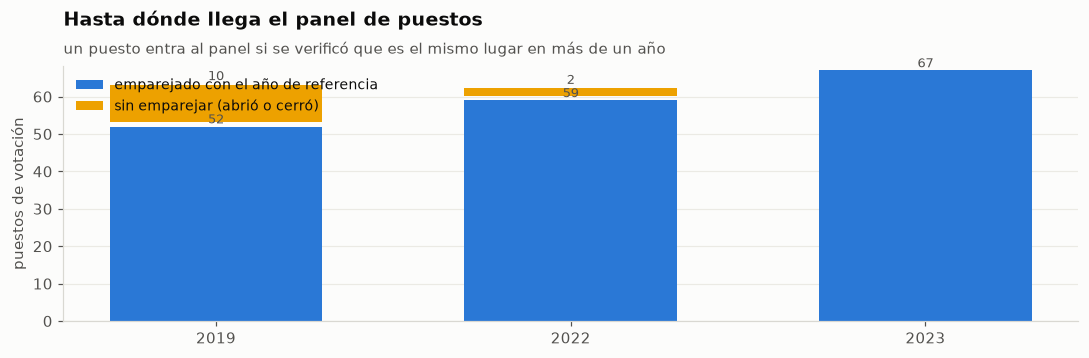

In [17]:
fig, ax = marco("Hasta dónde llega el panel de puestos",
                "un puesto entra al panel si se verificó que es el mismo lugar en más de un año",
                alto=3.4)
anios = inf_panel["anio"].astype(str).tolist()
x = np.arange(len(anios))
emp = inf_panel["emparejados"].values
sin = inf_panel["sin_emparejar"].values
b1 = ax.bar(x, emp, width=0.6, color=PALETA[0], label="emparejado con el año de referencia")
b2 = ax.bar(x, sin, width=0.6, bottom=emp + 1.2, color=PALETA[3],
            label="sin emparejar (abrió o cerró)")
etiquetar_barras_v(ax, b1, emp, fmt="{:.0f}")
for bb, v, base in zip(b2, sin, emp):
    if v:
        ax.text(bb.get_x() + bb.get_width() / 2, base + v + 2.4, "%d" % v,
                ha="center", fontsize=8.5, color=TINTA_2)
ax.set_xticks(x)
ax.set_xticklabels(anios)
ax.set_ylabel("puestos de votación")
ax.legend(loc="upper left")
guardar(fig, "03_cobertura_panel")
plt.show()

### 3.2. Controles del preprocesamiento

Los controles de criticidad alta deben aprobarse antes de usar los datasets. Los controles informativos se revisan como parte del diagnóstico.

In [18]:
ctrl = leer("controles_preparacion.csv")
ctrl["resultado"] = np.where(ctrl["pasa"].astype(str) == "True", "pasa", "FALLA")
print(ctrl[["control", "valor", "esperado", "criticidad", "resultado"]].to_string(index=False))

altos = ctrl[(ctrl["criticidad"] == "Alta") & (ctrl["resultado"] == "FALLA")]
print("\n" + ("Todos los controles de criticidad alta pasan." if not len(altos)
              else "ATENCIÓN: %d control(es) alto(s) fallan." % len(altos)))

                                            control                          valor                                               esperado criticidad resultado
 válidos + no válidos = depositados, en cada puesto                              0                                   0 filas descuadradas       Alta      pasa
       la tabla por puesto conserva todos los votos             1452467 vs 1452467                                                iguales       Alta      pasa
        ningún voto se perdió al convertir a número                              0                                 0 valores no numéricos       Alta      pasa
         todos los códigos quedaron del mismo ancho                todos correctos                               un solo ancho por código       Alta      pasa
      un puesto no se repite dentro de una elección                              0                                           0 duplicados       Alta      pasa
  todo puesto tiene ámbito urbano, rural o esp

### 3.3. Valores extremos

Los valores extremos se marcan para su revisión y se conservan en los datos.

In [19]:
pe = leer("puesto_eleccion.csv", dtype={"anio": str, "cod_zona": str,
                                       "cod_puesto": str, "cod_comuna": str})
marcas = [c for c in pe.columns if c.startswith("marca_")]
res = pd.DataFrame({
    "marca": marcas,
    "filas_marcadas": [int(pe[c].astype(str).eq("True").sum()) for c in marcas],
})
res["pct"] = (res["filas_marcadas"] / len(pe) * 100).round(1)
print("MARCAS SOBRE %d FILAS DE puesto × elección" % len(pe))
print(res[res["filas_marcadas"] > 0].to_string(index=False))

print("\nQué hay detrás de las marcas más llamativas:")
alto = pe[pe["marca_no_validos_altos"].astype(str) == "True"]
print("\n· no válidos por encima del 30 %% (%d filas):" % len(alto))
print(alto.groupby(["anio", "corporacion"]).size().to_string())
peq = pe[pe["marca_puesto_pequeno"].astype(str) == "True"]
print("\n· puestos con menos de 100 votos (%d filas):" % len(peq))
print(peq[["anio", "corporacion", "puesto", "votos_depositados",
           "ambito"]].head(8).to_string(index=False))

MARCAS SOBRE 770 FILAS DE puesto × elección
                       marca  filas_marcadas  pct
marca_participacion_muy_baja               1  0.1
         marca_sin_potencial              12  1.6
        marca_puesto_pequeno              13  1.7
      marca_no_validos_altos              29  3.8
       marca_ambito_especial              10  1.3

Qué hay detrás de las marcas más llamativas:

· no válidos por encima del 30 % (29 filas):
anio  corporacion
2019  ASAMBLEA        1
2023  ASAMBLEA        1
      GOBERNADOR     27

· puestos con menos de 100 votos (13 filas):
anio corporacion                                  puesto  votos_depositados   ambito
2022      CAMARA INST. TEC. SUPERIOR INDUSTRIAL - SEDE C                 95   urbano
2022      CAMARA                                  CARCEL                 54 especial
2022      SENADO INST. TEC. SUPERIOR INDUSTRIAL - SEDE C                 98   urbano
2022      SENADO                                  CARCEL                 54 especial
202

# Parte 4. Análisis exploratorio

Se describen los patrones observados en los datasets analíticos.

## 4.1. Participación y abstención

La participación corresponde a los votos depositados sobre el potencial electoral. Incluye votos válidos, en blanco, nulos y no marcados.

In [20]:
agg = leer("agregado_eleccion.csv", dtype={"anio": str})
agg = agg.sort_values(["corporacion", "anio"])
print(agg[["anio", "corporacion", "potencial_electoral", "votos_depositados",
           "participacion", "abstencion", "cobertura_del_censo"]].to_string(index=False))

print("\nCobertura del censo por debajo del 100 %% (el potencial no es el del distrito completo):")
inc = agg[agg["cobertura_del_censo"] < 100]
print(inc[["anio", "corporacion", "cobertura_del_censo"]].to_string(index=False)
      if len(inc) else "   ninguna")

anio corporacion  potencial_electoral  votos_depositados  participacion  abstencion  cobertura_del_censo
2019     ALCALDE             175303.0             121980          69.58       30.42                100.0
2023     ALCALDE             187483.0             132133          70.48       29.52                100.0
2019    ASAMBLEA             175303.0             119968          68.43       31.57                100.0
2023    ASAMBLEA             187483.0             128983          68.80       31.20                100.0
2022      CAMARA             166797.0             100605          60.32       39.68                 90.2
2019     CONCEJO             175303.0             121765          69.46       30.54                100.0
2023     CONCEJO             187483.0             131961          70.39       29.61                100.0
2019  GOBERNADOR             175303.0             120891          68.96       31.04                100.0
2023  GOBERNADOR             187483.0             12919

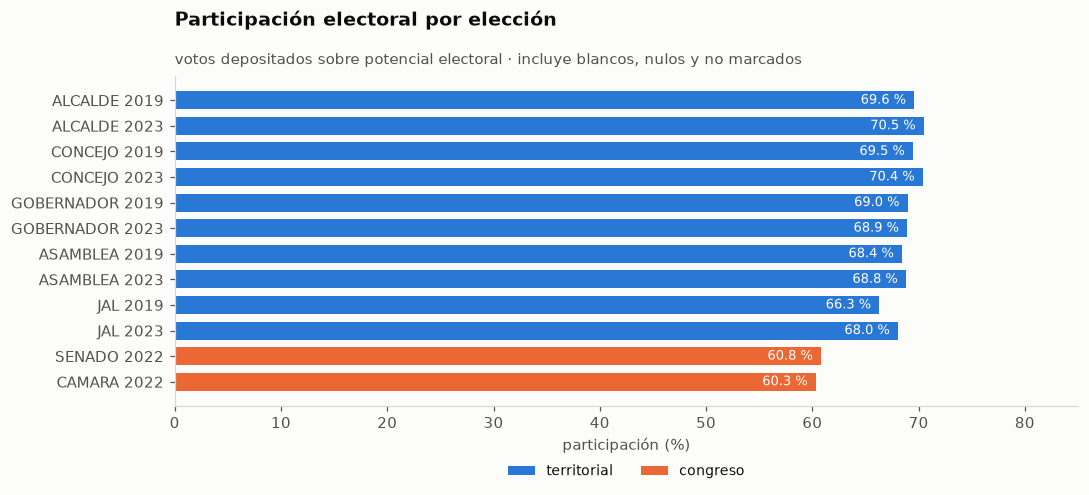

In [21]:
orden = ["ALCALDE", "CONCEJO", "GOBERNADOR", "ASAMBLEA", "JAL", "SENADO", "CAMARA"]
a = agg.copy()
a["corporacion"] = pd.Categorical(a["corporacion"], orden, ordered=True)
a = a.sort_values(["corporacion", "anio"])
a["etiqueta"] = a["corporacion"].astype(str) + " " + a["anio"]

col = [PALETA[0] if f == "territorial" else PALETA[1] for f in a["familia"]]
fig, ax = marco("Participación electoral por elección",
                "votos depositados sobre potencial electoral · incluye blancos, nulos y no marcados",
                alto=4.8, eje_y_grid=False)
ax.grid(axis="x")
b = ax.barh(a["etiqueta"], a["participacion"], color=col, height=0.7)
etiquetar_barras_h(ax, b, a["participacion"].values, fmt="{:.1f} %")
ax.set_xlabel("participación (%)")
ax.set_xlim(0, 85)
ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="territorial"),
                   Patch(facecolor=PALETA[1], label="congreso")],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
guardar(fig, "04_participacion_por_eleccion")
plt.show()

La participación en las elecciones territoriales se ubica entre 66 % y 70,5 %; en Congreso 2022, cerca de 60 %, una diferencia aproximada de diez puntos porcentuales. La comparación tiene una limitación: la cobertura del censo para Congreso es 90,2 %, por lo que el potencial registrado no corresponde al distrito completo.

## 4.2. Composición del voto

El voto en blanco es válido y cuenta para la cifra repartidora. Los votos nulos y no marcados no son válidos.

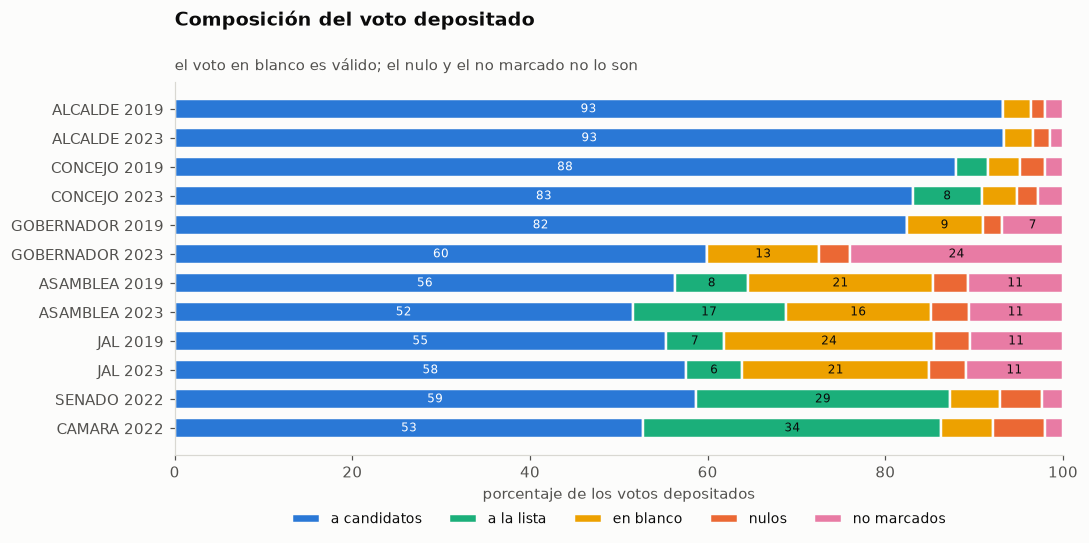

In [22]:
comp = a[["etiqueta", "votos_a_candidatos", "votos_de_lista", "votos_blanco",
          "votos_nulos", "votos_no_marcados", "votos_depositados"]].copy()
for c in ("votos_a_candidatos", "votos_de_lista", "votos_blanco", "votos_nulos",
          "votos_no_marcados"):
    comp[c + "_pct"] = comp[c] / comp["votos_depositados"] * 100

segmentos = [("votos_a_candidatos_pct", "a candidatos", PALETA[0]),
             ("votos_de_lista_pct", "a la lista", PALETA[2]),
             ("votos_blanco_pct", "en blanco", PALETA[3]),
             ("votos_nulos_pct", "nulos", PALETA[1]),
             ("votos_no_marcados_pct", "no marcados", PALETA[4])]

fig, ax = marco("Composición del voto depositado",
                "el voto en blanco es válido; el nulo y el no marcado no lo son",
                alto=5.2, eje_y_grid=False)
ax.grid(axis="x")
y = np.arange(len(comp))
izq = np.zeros(len(comp))
for cl, nombre, color in segmentos:
    v = comp[cl].values
    ax.barh(y, v, left=izq, height=0.68, color=color, label=nombre,
            edgecolor=SUPERFICIE, linewidth=1.6)  # 2px de separación entre segmentos
    for i, (vi, li) in enumerate(zip(v, izq)):
        if vi >= 6:
            ax.text(li + vi / 2, i, "%.0f" % vi, ha="center", va="center",
                    fontsize=8, color="white" if color in (PALETA[0], PALETA[1]) else TINTA)
    izq += v
ax.set_yticks(y)
ax.set_yticklabels(comp["etiqueta"])
ax.invert_yaxis()
ax.set_xlabel("porcentaje de los votos depositados")
ax.set_xlim(0, 100)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
guardar(fig, "05_composicion_del_voto")
plt.show()

In [23]:
print("LAS ELECCIONES CON MÁS VOTO NO VÁLIDO")
nv = a[["anio", "corporacion", "pct_blanco", "pct_nulos", "pct_no_marcados",
        "pct_no_validos"]].sort_values("pct_no_validos", ascending=False)
print(nv.head(6).to_string(index=False))
print("\nGobernación 2023 destaca: %.1f %% de los votos depositados no fueron válidos,"
      % a[(a.anio == "2023") & (a.corporacion == "GOBERNADOR")]["pct_no_validos"].iloc[0])
print("y la mayor parte son tarjetas NO MARCADAS (%.1f %%), no nulas."
      % a[(a.anio == "2023") & (a.corporacion == "GOBERNADOR")]["pct_no_marcados"].iloc[0])
print("\nEso describe un patrón: muchas personas recibieron la tarjeta de Gobernación")
print("y la depositaron sin marcarla. NO es evidencia de irregularidad; es una")
print("descripción de lo que quedó registrado en las actas.")

LAS ELECCIONES CON MÁS VOTO NO VÁLIDO
anio corporacion  pct_blanco  pct_nulos  pct_no_marcados  pct_no_validos
2023  GOBERNADOR       12.62       3.47            23.95           27.42
2023         JAL       21.09       4.11            10.94           15.04
2023    ASAMBLEA       16.39       4.21            10.64           14.84
2019    ASAMBLEA       20.73       3.96            10.73           14.68
2019         JAL       23.71       3.95            10.52           14.47
2019  GOBERNADOR        8.54       2.23             6.81            9.05

Gobernación 2023 destaca: 27.4 % de los votos depositados no fueron válidos,
y la mayor parte son tarjetas NO MARCADAS (23.9 %), no nulas.

Eso describe un patrón: muchas personas recibieron la tarjeta de Gobernación
y la depositaron sin marcarla. NO es evidencia de irregularidad; es una
descripción de lo que quedó registrado en las actas.


## 4.3. Distribución por puesto

La distribución por puesto muestra variaciones que no se observan en los agregados del distrito.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


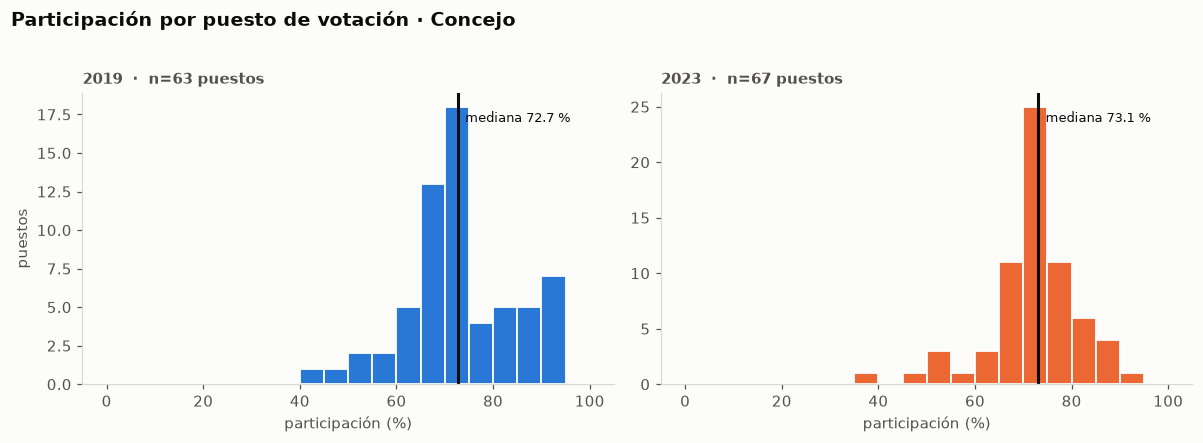

Resumen por ámbito, Concejo 2023:
          count  median   min   max
ambito                             
especial      1    37.6  37.6  37.6
rural        11    76.3  58.6  91.6
urbano       55    73.1  45.7  86.4


In [24]:
conc = pe[(pe["corporacion"] == "CONCEJO") & pe["participacion"].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.9))
fig.suptitle("Participación por puesto de votación · Concejo", x=0.01, ha="left",
             y=1.02, fontsize=12.5, fontweight="semibold", color=TINTA)
for ax, anio, color in zip(axes, ["2019", "2023"], PALETA[:2]):
    v = conc[conc["anio"] == anio]["participacion"]
    ax.hist(v, bins=np.arange(0, 105, 5), color=color, edgecolor=SUPERFICIE,
            linewidth=1.2)
    ax.axvline(v.median(), color=TINTA, lw=2)
    ax.text(v.median() + 1.5, ax.get_ylim()[1] * 0.9, "mediana %.1f %%" % v.median(),
            fontsize=8.5, color=TINTA)
    ax.set_title("%s  ·  n=%d puestos" % (anio, len(v)), loc="left", fontsize=10,
                 color=TINTA_2)
    ax.set_xlabel("participación (%)")
    ax.grid(axis="y")
axes[0].set_ylabel("puestos")
fig.tight_layout()
fig.savefig(FIGURAS / "06_distribucion_participacion.png", bbox_inches="tight")
plt.show()

print("Resumen por ámbito, Concejo 2023:")
print(conc[conc["anio"] == "2023"].groupby("ambito")["participacion"]
      .agg(["count", "median", "min", "max"]).round(1).to_string())

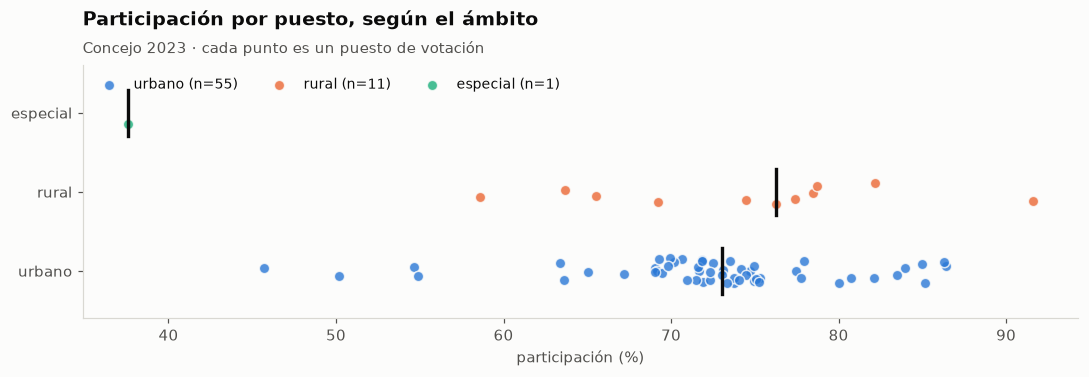

El punto solitario de abajo a la izquierda es la cárcel (zona 98): un puesto real
con 149 electores, censo 96 %% masculino, que no se parece a ningún otro.
Está marcado con `marca_ambito_especial` para que cualquier agrupamiento
decida explícitamente si lo incluye.


In [25]:
c23 = conc[conc["anio"] == "2023"]
fig, ax = marco("Participación por puesto, según el ámbito",
                "Concejo 2023 · cada punto es un puesto de votación",
                alto=3.6, eje_y_grid=False)
ax.grid(axis="x")
ambitos = ["urbano", "rural", "especial"]
rng = np.random.default_rng(11)
for i, (amb, color) in enumerate(zip(ambitos, PALETA_TODOS_LOS_PARES)):
    v = c23[c23["ambito"] == amb]["participacion"]
    if not len(v):
        continue
    y = np.full(len(v), i) + rng.uniform(-0.16, 0.16, len(v))
    ax.scatter(v, y, s=46, color=color, alpha=0.8, edgecolor=SUPERFICIE,
               linewidth=1.0, zorder=3, label="%s (n=%d)" % (amb, len(v)))
    ax.plot([v.median()] * 2, [i - 0.29, i + 0.29], color=TINTA, lw=2.2, zorder=4)
ax.set_yticks(range(len(ambitos)))
ax.set_yticklabels(ambitos)
ax.set_xlabel("participación (%)")
ax.set_ylim(-0.6, 2.6)
ax.legend(loc="upper left", ncol=3)
guardar(fig, "07_participacion_por_ambito")
plt.show()

print("El punto solitario de abajo a la izquierda es la cárcel (zona 98): un puesto real")
print("con 149 electores, censo 96 %% masculino, que no se parece a ningún otro.")
print("Está marcado con `marca_ambito_especial` para que cualquier agrupamiento")
print("decida explícitamente si lo incluye.")

## 4.4. Distribución territorial

Participación por comuna y corregimiento. El mapa utiliza geometrías de OpenStreetMap.

In [26]:
terr = leer("agregado_territorio.csv", dtype={"anio": str, "cod_comuna": str})
t23 = terr[(terr["anio"] == "2023") & (terr["corporacion"] == "CONCEJO")].copy()
t23 = t23.sort_values("participacion")
print(t23[["cod_comuna", "territorio", "ambito", "puestos", "potencial_electoral",
           "votos_depositados", "participacion"]].to_string(index=False))

cod_comuna                          territorio   ambito  puestos  potencial_electoral  votos_depositados  participacion
        00                              CARCEL especial        1                149.0                 56          37.58
        11  CORREGIMIENTO MESETA DE SAN RAFAEL    rural        1                621.0                364          58.62
        02                            COMUNA 2   urbano        7              26994.0              16633          61.62
        10  CORREGIMIENTO LA FORTUNA AUTOPISTA    rural        1               2021.0               1287          63.68
        12 CORREGIMIENTO SAN RAFAEL DE CHUCURI    rural        1                649.0                425          65.49
        13      CORREGIMIENTO CIENAGA DEL OPON    rural        1                361.0                250          69.25
        06                            COMUNA 6   urbano        5              16438.0              11423          69.49
        04                            CO

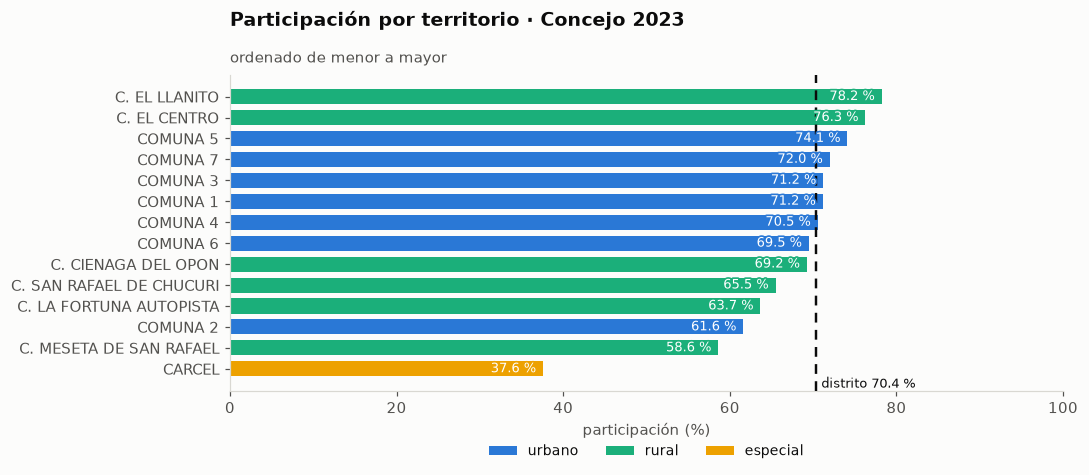

In [27]:
col = [PALETA[0] if x == "urbano" else (PALETA[2] if x == "rural" else PALETA[3])
       for x in t23["ambito"]]
fig, ax = marco("Participación por territorio · Concejo 2023",
                "ordenado de menor a mayor", alto=4.6, eje_y_grid=False)
ax.grid(axis="x")
etq = t23["territorio"].str.replace("CORREGIMIENTO ", "C. ", regex=False)
b = ax.barh(etq, t23["participacion"], color=col, height=0.72)
etiquetar_barras_h(ax, b, t23["participacion"].values, fmt="{:.1f} %")
media = agg[(agg.anio == "2023") & (agg.corporacion == "CONCEJO")]["participacion"].iloc[0]
ax.axvline(media, color=TINTA, lw=1.6, ls=(0, (4, 3)), zorder=4)
ax.text(media + 0.6, -0.9, "distrito %.1f %%" % media, fontsize=8.5, color=TINTA)
ax.set_xlabel("participación (%)")
ax.set_xlim(0, 100)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="urbano"),
                   Patch(facecolor=PALETA[2], label="rural"),
                   Patch(facecolor=PALETA[3], label="especial")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
guardar(fig, "08_participacion_por_territorio")
plt.show()

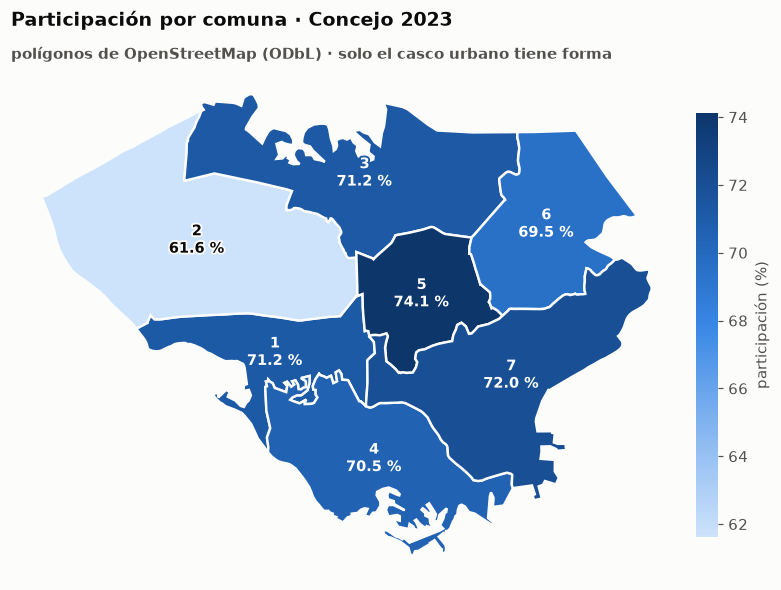

Los corregimientos NO aparecen en el mapa: OpenStreetMap no los tiene como
polígono, solo como punto. Un mapa que les inventara un área sería falso.


In [29]:
# ---- Mapa de comunas, con los polígonos de OpenStreetMap ----
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon

ruta_geo = GEO / "limites_administrativos.geojson"
if not ruta_geo.exists():
    print("No hay geometría todavía. Corre src/geoespacial/osm.py primero.")
else:
    import re as _re
    gj = json.loads(ruta_geo.read_text(encoding="utf-8"))
    comunas = []
    for f in gj["features"]:
        p = f["properties"]
        m = _re.search(r"Comuna\s+(\d+)", p.get("nombre", ""))
        if p.get("admin_level") == "8" and m:
            geom = f["geometry"]
            polis = ([geom["coordinates"]] if geom["type"] == "Polygon"
                     else geom["coordinates"])
            comunas.append({"cod_comuna": m.group(1).zfill(2),
                            "numero": int(m.group(1)), "poligonos": polis})

    valores = dict(zip(t23["cod_comuna"], t23["participacion"]))
    vv = [valores.get(c["cod_comuna"]) for c in comunas]
    vv = [v for v in vv if v is not None]
    vmin, vmax = min(vv), max(vv)
    rampa = mpl.colors.LinearSegmentedColormap.from_list("seq", SECUENCIAL)
    norma = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

    fig, ax = plt.subplots(figsize=(7.2, 7.4))
    ax.text(0, 1.08, "Participación por comuna · Concejo 2023", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12.5, fontweight="semibold", color=TINTA)
    ax.set_title("polígonos de OpenStreetMap (ODbL) · solo el casco urbano tiene forma",
                 loc="left", fontsize=9.5, color=TINTA_2, pad=8)
    def centroide_de_area(anillo):
        """Centroide del area, no el promedio de los vertices.

        Importa: la comuna 1 tiene una cola larga y estrecha, y el promedio de los
        vertices cae fuera de la parte ancha, asi que la etiqueta se salia del
        poligono. El centroide del area cae donde esta la masa de la figura.
        """
        p = np.asarray(anillo, dtype=float)
        if not np.allclose(p[0], p[-1]):
            p = np.vstack([p, p[0]])
        x, y = p[:, 0], p[:, 1]
        cruz = x[:-1] * y[1:] - x[1:] * y[:-1]
        area = cruz.sum() / 2.0
        if abs(area) < 1e-12:
            return x.mean(), y.mean()
        cx = ((x[:-1] + x[1:]) * cruz).sum() / (6 * area)
        cy = ((y[:-1] + y[1:]) * cruz).sum() / (6 * area)
        return cx, cy

    for c in comunas:
        v = valores.get(c["cod_comuna"])
        color = rampa(norma(v)) if v is not None else "#e8e7e2"
        mayor, area_mayor = None, -1.0
        for poli in c["poligonos"]:
            ext = np.array(poli[0])
            ax.add_patch(MplPolygon(ext, closed=True, facecolor=color,
                                    edgecolor=SUPERFICIE, linewidth=1.6, zorder=2))
            anillo = ext if np.allclose(ext[0], ext[-1]) else np.vstack([ext, ext[0]])
            a = abs((anillo[:-1, 0] * anillo[1:, 1] - anillo[1:, 0] * anillo[:-1, 1]).sum()) / 2.0
            if a > area_mayor:
                mayor, area_mayor = ext, a
        cx, cy = centroide_de_area(mayor)
        # Etiqueta directa: el color no carga el dato solo. El texto va claro sobre
        # los pasos oscuros de la rampa y oscuro sobre los claros.
        claro = v is None or norma(v) < 0.55
        ax.text(cx, cy,
                "%d\n%.1f %%" % (c["numero"], v) if v is not None else str(c["numero"]),
                ha="center", va="center", fontsize=9.5,
                color=TINTA if claro else "white", fontweight="semibold", zorder=4,
                path_effects=[mpl.patheffects.withStroke(
                    linewidth=2.4, foreground=SUPERFICIE if claro else color)])
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.radians(7.06)))
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.grid(False)
    sm = mpl.cm.ScalarMappable(norm=norma, cmap=rampa)
    cb = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cb.set_label("participación (%)", color=TINTA_2)
    cb.outline.set_visible(False)
    fig.tight_layout()
    fig.savefig(FIGURAS / "09_mapa_participacion_comunas.png", bbox_inches="tight")
    plt.show()
    print("Los corregimientos NO aparecen en el mapa: OpenStreetMap no los tiene como")
    print("polígono, solo como punto. Un mapa que les inventara un área sería falso.")

## 4.5. Fragmentación y oferta electoral

El número efectivo de partidos de Laakso-Taagepera se calcula como el inverso del índice HHI. Resume la distribución del voto entre listas y no equivale al número de listas inscritas.

In [30]:
con = leer("concentracion_eleccion.csv", dtype={"anio": str})
ofe = leer("oferta_electoral.csv", dtype={"anio": str})
j = con.merge(ofe[["anio", "corporacion", "candidatos_con_al_menos_un_voto",
                   "listas_con_candidatos"]], on=["anio", "corporacion"])
print(j[["anio", "corporacion", "listas_con_votos", "listas_sin_voto_preferente",
         "candidatos_con_al_menos_un_voto", "hhi", "numero_efectivo_de_partidos",
         "pct_de_la_lista_mayor"]].to_string(index=False))

anio corporacion  listas_con_votos  listas_sin_voto_preferente  candidatos_con_al_menos_un_voto    hhi  numero_efectivo_de_partidos  pct_de_la_lista_mayor
2019     ALCALDE                 6                           0                                6 0.3459                         2.89                  49.10
2019    ASAMBLEA                14                           2                              167 0.1303                         7.67                  21.10
2019     CONCEJO                18                           1                              275 0.0781                        12.80                  11.87
2019  GOBERNADOR                 6                           0                                6 0.3076                         3.25                  42.17
2019         JAL                12                           1                               63 0.1222                         8.18                  17.14
2022      CAMARA                63                          33        

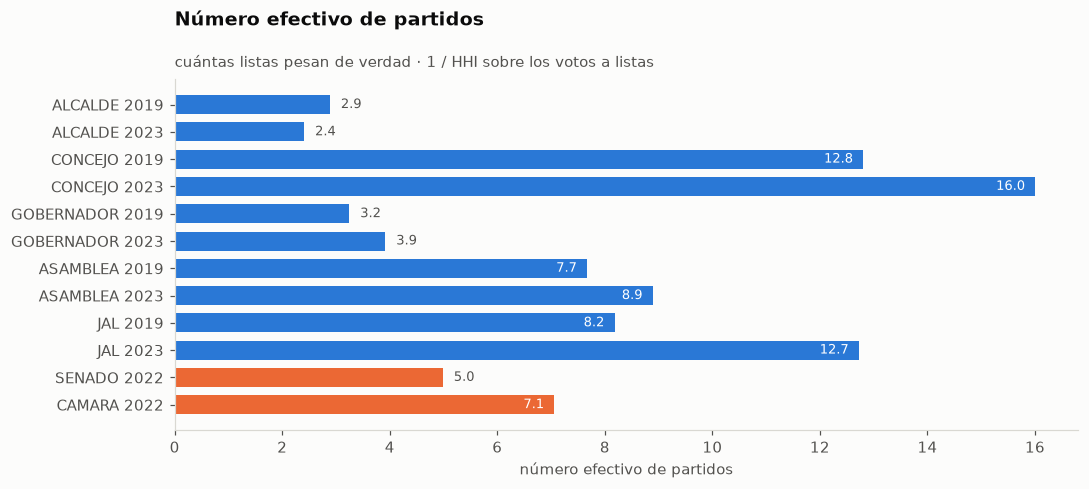

El Concejo es la elección más fragmentada del distrito y se fragmentó más:
   2019: 18 listas con votos, número efectivo 12.8, la mayor con 11.9 %
   2023: 25 listas con votos, número efectivo 16.0, la mayor con 12.8 %

Alcaldía y Gobernación, que son uninominales, están en el extremo opuesto:
2 o 3 opciones concentran casi todo.


In [31]:
c = con.copy()
c["corporacion"] = pd.Categorical(c["corporacion"], orden, ordered=True)
c = c.sort_values(["corporacion", "anio"])
c["etiqueta"] = c["corporacion"].astype(str) + " " + c["anio"]
col = [PALETA[0] if f == "territorial" else PALETA[1]
       for f in c.merge(agg[["anio", "corporacion", "familia"]],
                        on=["anio", "corporacion"])["familia"]]

fig, ax = marco("Número efectivo de partidos",
                "cuántas listas pesan de verdad · 1 / HHI sobre los votos a listas",
                alto=4.6, eje_y_grid=False)
ax.grid(axis="x")
b = ax.barh(c["etiqueta"], c["numero_efectivo_de_partidos"], color=col, height=0.7)
etiquetar_barras_h(ax, b, c["numero_efectivo_de_partidos"].values, fmt="{:.1f}")
ax.set_xlabel("número efectivo de partidos")
ax.invert_yaxis()
guardar(fig, "10_numero_efectivo_de_partidos")
plt.show()

print("El Concejo es la elección más fragmentada del distrito y se fragmentó más:")
cc = c[c["corporacion"] == "CONCEJO"]
for _, r in cc.iterrows():
    print("   %s: %d listas con votos, número efectivo %.1f, la mayor con %.1f %%"
          % (r["anio"], r["listas_con_votos"], r["numero_efectivo_de_partidos"],
             r["pct_de_la_lista_mayor"]))
print("\nAlcaldía y Gobernación, que son uninominales, están en el extremo opuesto:")
print("2 o 3 opciones concentran casi todo.")

### Volatilidad electoral

El índice de Pedersen mide el cambio en la distribución del voto entre listas. Como estas pueden cambiar de nombre o coaligarse entre elecciones, el indicador también puede reflejar esos cambios. Cada resultado incluye una nota interpretativa y la proporción del voto correspondiente a listas presentes en ambos años. En Alcaldía no hay listas en común.

In [32]:
vol = leer("volatilidad.csv", dtype={"de": str, "a": str})
print(vol[["corporacion", "de", "a", "volatilidad_pedersen", "listas_en_ambas",
           "pct_del_voto_en_listas_continuas", "lectura"]].to_string(index=False))

print("\nPor qué Alcaldía da exactamente 100:")
for anio in ("2019", "2023"):
    nombres = sorted(set(larga[(larga["anio"] == anio)
                               & (larga["corporacion"] == "ALCALDE")
                               & (larga["tipo_opcion"].isin(["candidato", "lista"]))
                               ]["nombre_partido"].dropna()))
    print("   %s: %s" % (anio, nombres[:5]))
print("\nNo se repite ni una. En Alcaldía se compite bajo coaliciones armadas para cada")
print("elección, así que el 100 es aritméticamente correcto y sustantivamente vacío.")

corporacion   de    a  volatilidad_pedersen  listas_en_ambas  pct_del_voto_en_listas_continuas                                                                                                    lectura
    ALCALDE 2019 2023                100.00                0                               0.0 NO INTERPRETABLE: ninguna lista aparece en las dos elecciones, el indice solo refleja el cambio de nombres
   ASAMBLEA 2019 2023                 79.74                3                              33.7                          CON CAUTELA: menos de la mitad del voto esta en listas presentes en los dos anios
    CONCEJO 2019 2023                 82.95                4                              25.1                          CON CAUTELA: menos de la mitad del voto esta en listas presentes en los dos anios
 GOBERNADOR 2019 2023                 77.75                1                              32.2                          CON CAUTELA: menos de la mitad del voto esta en listas presentes en los 

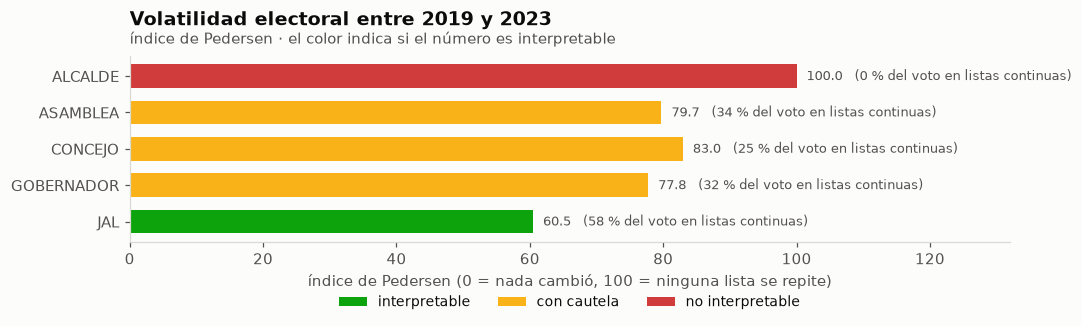

In [33]:
v = vol.copy()
estado_color = {"interpretable": ESTADO["bien"]}
colores_v = []
for lec in v["lectura"]:
    if lec.startswith("NO INTERPRETABLE"):
        colores_v.append(ESTADO["critico"])
    elif lec.startswith("CON CAUTELA"):
        colores_v.append(ESTADO["aviso"])
    else:
        colores_v.append(ESTADO["bien"])

fig, ax = marco("Volatilidad electoral entre 2019 y 2023",
                "índice de Pedersen · el color indica si el número es interpretable",
                alto=3.4, eje_y_grid=False)
ax.grid(axis="x")
b = ax.barh(v["corporacion"], v["volatilidad_pedersen"], color=colores_v, height=0.65)
for bb, val, cont in zip(b, v["volatilidad_pedersen"], v["pct_del_voto_en_listas_continuas"]):
    ax.text(val + 1.5, bb.get_y() + bb.get_height() / 2,
            "%.1f   (%.0f %% del voto en listas continuas)" % (val, cont),
            va="center", fontsize=8.5, color=TINTA_2)
ax.set_xlabel("índice de Pedersen (0 = nada cambió, 100 = ninguna lista se repite)")
ax.set_xlim(0, 132)
ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=ESTADO["bien"], label="interpretable"),
                   Patch(facecolor=ESTADO["aviso"], label="con cautela"),
                   Patch(facecolor=ESTADO["critico"], label="no interpretable")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
guardar(fig, "11_volatilidad")
plt.show()

## 4.6. Persistencia de la participación por puesto

El análisis utiliza los puestos del panel cuya identidad se verificó entre elecciones. Los códigos originales no permiten asegurar esa correspondencia.

Puestos del panel con participación en los dos años: 52


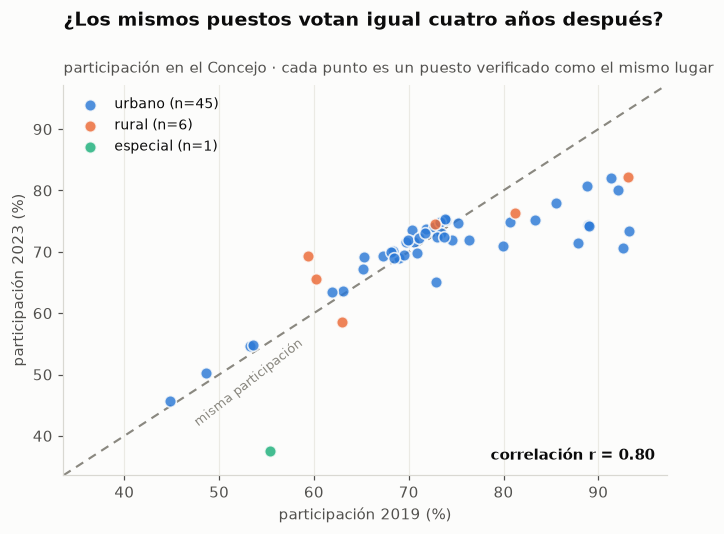


Correlación de la participación del mismo puesto entre 2019 y 2023: r = 0.80
Los puestos por encima de la diagonal subieron su participación; los de abajo
la bajaron. Una correlación alta indica que el nivel de participación de un
puesto es una característica persistente del territorio, no un accidente.


In [34]:
pp = leer("panel_participacion.csv")
cols = [c for c in pp.columns if c.startswith("CONCEJO_")]
print("Puestos del panel con participación en los dos años: %d"
      % pp[cols].dropna().shape[0] if len(cols) >= 2 else 0)

if len(cols) >= 2:
    d = pp.dropna(subset=cols).copy()
    x, y = d[cols[0]], d[cols[1]]
    r = np.corrcoef(x, y)[0, 1]

    fig, ax = marco("¿Los mismos puestos votan igual cuatro años después?",
                    "participación en el Concejo · cada punto es un puesto verificado como el mismo lugar",
                    alto=5.0, ancho=6.6)
    lim = [min(x.min(), y.min()) - 4, max(x.max(), y.max()) + 4]
    ax.plot(lim, lim, color=TINTA_3, lw=1.4, ls=(0, (4, 3)), zorder=1)
    medio = lim[0] + (lim[1] - lim[0]) * 0.30
    ax.text(medio, medio - 3.2, "misma participación", fontsize=8.5,
            color=TINTA_3, ha="center", va="top", rotation=38,
            rotation_mode="anchor")
    colores_a = {"urbano": PALETA[0], "rural": PALETA[1], "especial": PALETA[2]}
    for amb, col_ in colores_a.items():
        s = d[d["ambito"] == amb]
        if len(s):
            ax.scatter(s[cols[0]], s[cols[1]], s=58, color=col_, alpha=0.82,
                       edgecolor=SUPERFICIE, linewidth=1.1, zorder=3,
                       label="%s (n=%d)" % (amb, len(s)))
    ax.set_xlabel("participación 2019 (%)")
    ax.set_ylabel("participación 2023 (%)")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.grid(axis="both")
    ax.legend(loc="upper left")
    ax.text(0.98, 0.04, "correlación r = %.2f" % r, transform=ax.transAxes,
            ha="right", fontsize=10, color=TINTA, fontweight="semibold")
    guardar(fig, "12_persistencia_participacion")
    plt.show()

    print("\nCorrelación de la participación del mismo puesto entre 2019 y 2023: r = %.2f" % r)
    print("Los puestos por encima de la diagonal subieron su participación; los de abajo")
    print("la bajaron. Una correlación alta indica que el nivel de participación de un")
    print("puesto es una característica persistente del territorio, no un accidente.")

## 4.7. Censo y participación

Se relaciona la composición etaria del censo de cada puesto con su participación. La asociación observada entre puestos no permite concluir que las personas jóvenes voten menos: los datos no identifican la edad de quienes votaron. Atribuir a individuos una relación observada en datos agregados constituye una falacia ecológica.

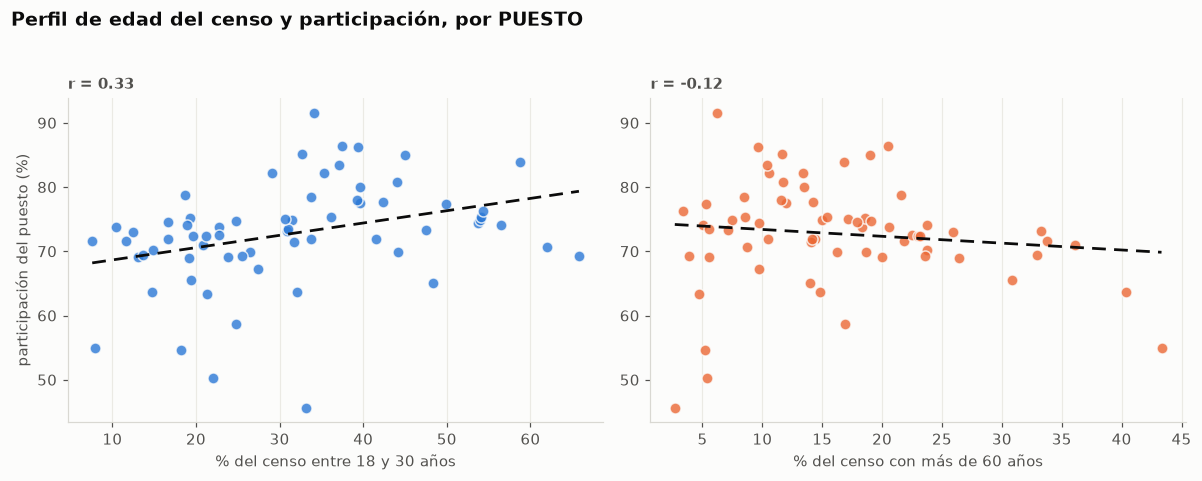

ADVERTENCIA METODOLÓGICA
Esto describe PUESTOS, no personas. Un puesto con censo joven y participación
baja no permite concluir que los jóvenes de ese puesto no votaron: pudo votar
cualquier composición de edades que sume ese total. La relación es real a nivel
de territorio y no se puede bajar al nivel individual.


In [35]:
d = c23[c23["pct_censo_18_a_30"].notna() & (c23["ambito"] != "especial")].copy()

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
fig.suptitle("Perfil de edad del censo y participación, por PUESTO",
             x=0.01, ha="left", y=1.03, fontsize=12.5, fontweight="semibold", color=TINTA)
for ax, var, etiqueta, color in zip(
        axes, ["pct_censo_18_a_30", "pct_censo_mas_de_60"],
        ["% del censo entre 18 y 30 años", "% del censo con más de 60 años"],
        PALETA[:2]):
    ax.scatter(d[var], d["participacion"], s=52, color=color, alpha=0.8,
               edgecolor=SUPERFICIE, linewidth=1.0, zorder=3)
    z = np.polyfit(d[var], d["participacion"], 1)
    xs = np.linspace(d[var].min(), d[var].max(), 20)
    ax.plot(xs, np.polyval(z, xs), color=TINTA, lw=1.8, ls=(0, (5, 3)), zorder=4)
    r = np.corrcoef(d[var], d["participacion"])[0, 1]
    ax.set_title("r = %.2f" % r, loc="left", fontsize=10, color=TINTA_2)
    ax.set_xlabel(etiqueta)
    ax.grid(axis="both")
axes[0].set_ylabel("participación del puesto (%)")
fig.tight_layout()
fig.savefig(FIGURAS / "13_censo_y_participacion.png", bbox_inches="tight")
plt.show()

print("ADVERTENCIA METODOLÓGICA")
print("Esto describe PUESTOS, no personas. Un puesto con censo joven y participación")
print("baja no permite concluir que los jóvenes de ese puesto no votaron: pudo votar")
print("cualquier composición de edades que sume ese total. La relación es real a nivel")
print("de territorio y no se puede bajar al nivel individual.")

## 4.8. Relación entre variables por puesto

La matriz por puesto puede utilizarse en análisis de componentes principales, agrupamiento o análisis espacial. La correlación entre variables permite identificar redundancias que pueden afectar estos análisis.

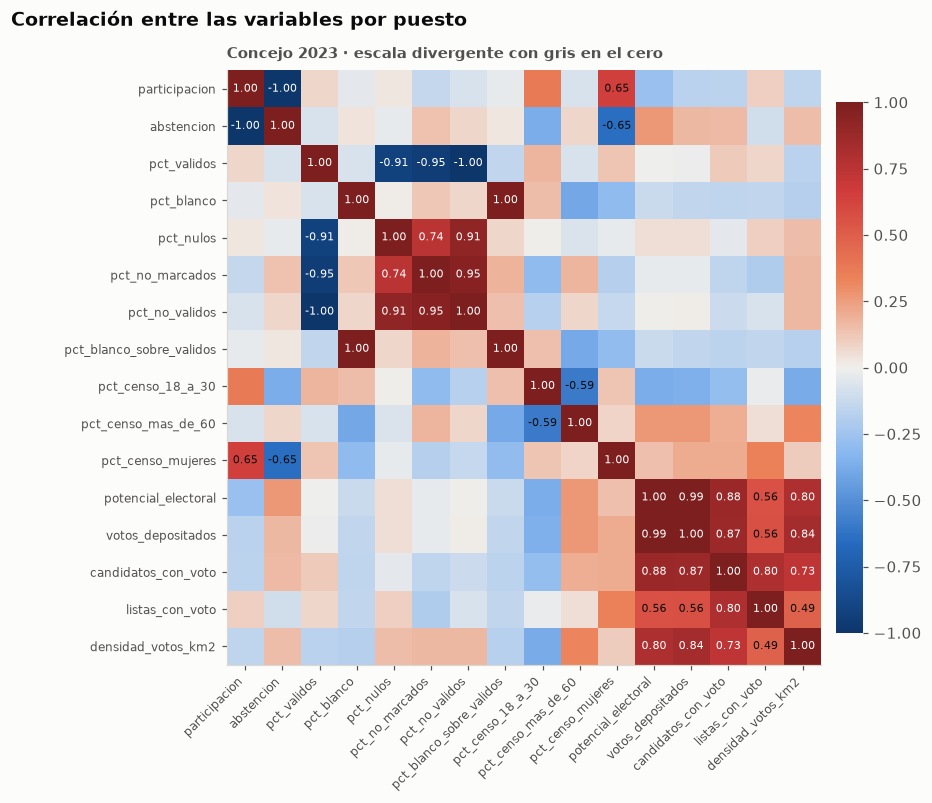

PARES MUY CORRELACIONADOS (|r| >= 0.9): aportan una sola dimensión
         variable_a               variable_b      r
      participacion               abstencion -1.000
        pct_validos                pct_nulos -0.915
        pct_validos          pct_no_marcados -0.950
        pct_validos           pct_no_validos -1.000
         pct_blanco pct_blanco_sobre_validos  0.997
          pct_nulos           pct_no_validos  0.915
    pct_no_marcados           pct_no_validos  0.950
potencial_electoral        votos_depositados  0.989


In [36]:
mat = leer("matriz_puesto_concejo_2023.csv")
num = mat.select_dtypes(include=[np.number])
# `cod_zona` y `cod_comuna` se leen como números pero son códigos: correlacionar
# el número de una comuna no significa nada y ensucia la matriz. Fuera.
num = num.drop(columns=[c for c in num.columns
                        if c.startswith("marca_")
                        or c in ("lon", "lat", "cod_zona", "cod_comuna",
                                 "cod_puesto", "marcas_activas")],
               errors="ignore")
num = num.loc[:, num.notna().sum() > len(num) * 0.6]
corr = num.corr()

fig, ax = plt.subplots(figsize=(8.6, 7.4))
fig.suptitle("Correlación entre las variables por puesto", x=0.02, ha="left", y=0.98,
             fontsize=12.5, fontweight="semibold", color=TINTA)
ax.set_title("Concejo 2023 · escala divergente con gris en el cero", loc="left",
             fontsize=9.5, color=TINTA_2, pad=8)
rampa_div = mpl.colors.LinearSegmentedColormap.from_list("div", DIVERGENTE)
im = ax.imshow(corr.values, cmap=rampa_div, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        if abs(v) >= 0.45:
            ax.text(j, i, "%.2f" % v, ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.72 else TINTA)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / "14_correlaciones_matriz_puesto.png", bbox_inches="tight")
plt.show()

print("PARES MUY CORRELACIONADOS (|r| >= 0.9): aportan una sola dimensión")
pares = []
for i in range(len(corr)):
    for j in range(i + 1, len(corr)):
        if abs(corr.values[i, j]) >= 0.9:
            pares.append((corr.columns[i], corr.columns[j],
                          round(corr.values[i, j], 3)))
print(pd.DataFrame(pares, columns=["variable_a", "variable_b", "r"]).to_string(index=False)
      if pares else "   ninguno")

# Parte 5. Datasets analíticos

Los archivos generados se guardan en `datos/analitico/`. La tabla principal, `puesto_eleccion.csv`, contiene una fila por puesto y elección, con el desglose de votos, censo, territorio, coordenadas y marcas.

In [37]:
inv = leer("inventario_datasets.csv")
print(inv.to_string(index=False))
print("\nTotal: %d datasets, %s filas escritas."
      % (len(inv), "{:,}".format(int(inv["filas"].sum()))))

                                                  dataset                          archivo  filas  columnas
             voto por mesa y opción, todas las elecciones                   votos_mesa.csv 302979        25
                  TABLA PRINCIPAL: un puesto por elección              puesto_eleccion.csv    770        70
                   identidad estable de puesto entre años                panel_puestos.csv    190        14
                        totales del distrito por elección            agregado_eleccion.csv     12        25
                       totales por comuna y corregimiento          agregado_territorio.csv    164        18
                         votos de cada lista por elección             partido_eleccion.csv    226        11
                        HHI y número efectivo de partidos       concentracion_eleccion.csv     12         9
                      índice de Pedersen entre elecciones                  volatilidad.csv      5         9
                      listas

In [38]:
print("TABLA PRINCIPAL · puesto_eleccion.csv")
print("%d filas × %d columnas\n" % pe.shape)
grupos = {
    "identificación": ["anio", "familia", "corporacion", "es_uninominal", "cod_zona",
                       "cod_puesto", "puesto", "id_puesto"],
    "identidad de panel": ["id_panel", "en_panel", "en_panel_completo",
                           "anios_presentes", "parecido_con_referencia"],
    "territorio": ["cod_comuna", "territorio", "ambito", "origen_del_ambito",
                   "area_km2", "densidad_votos_km2"],
    "geografía": ["lon", "lat", "parecido_geocodificacion",
                  "puestos_que_comparten_punto"],
    "votación": ["mesas", "votos_depositados", "votos_validos", "votos_no_validos",
                 "votos_a_candidatos", "votos_de_lista", "votos_blanco",
                 "votos_nulos", "votos_no_marcados", "candidatos_con_voto",
                 "listas_con_voto"],
    "proporciones": [c for c in pe.columns if c.startswith("pct_")],
    "censo": ["potencial_electoral", "participacion", "abstencion"]
             + [c for c in pe.columns if c.startswith(("sexo_", "edad_"))],
    "marcas": [c for c in pe.columns if c.startswith("marca_")] + ["marcas_activas"],
}
for g, cs in grupos.items():
    presentes = [c for c in cs if c in pe.columns]
    print("%-22s %2d columnas" % (g, len(presentes)))
    print("   %s\n" % ", ".join(presentes))

faltan = set(pe.columns) - {c for cs in grupos.values() for c in cs}
if faltan:
    print("otras:", sorted(faltan))

TABLA PRINCIPAL · puesto_eleccion.csv
770 filas × 70 columnas

identificación          8 columnas
   anio, familia, corporacion, es_uninominal, cod_zona, cod_puesto, puesto, id_puesto

identidad de panel      5 columnas
   id_panel, en_panel, en_panel_completo, anios_presentes, parecido_con_referencia

territorio              6 columnas
   cod_comuna, territorio, ambito, origen_del_ambito, area_km2, densidad_votos_km2

geografía               4 columnas
   lon, lat, parecido_geocodificacion, puestos_que_comparten_punto

votación               11 columnas
   mesas, votos_depositados, votos_validos, votos_no_validos, votos_a_candidatos, votos_de_lista, votos_blanco, votos_nulos, votos_no_marcados, candidatos_con_voto, listas_con_voto

proporciones            9 columnas
   pct_validos, pct_blanco, pct_nulos, pct_no_marcados, pct_blanco_sobre_validos, pct_censo_18_a_30, pct_censo_mas_de_60, pct_censo_mujeres, pct_no_validos

censo                  18 columnas
   potencial_electoral, partic

In [39]:
print("CÓMO USAR LA TABLA PRINCIPAL\n")
print("# Participación del Concejo 2023 por comuna, solo lo urbano:")
print(">>> d = pd.read_csv('datos/analitico/puesto_eleccion.csv')")
print(">>> d[(d.anio==2023) & (d.corporacion=='CONCEJO') & (d.ambito=='urbano')]")
print("...     .groupby('territorio')[['votos_depositados','potencial_electoral']].sum()\n")

ej = pe[(pe["anio"] == "2023") & (pe["corporacion"] == "CONCEJO")
        & (pe["ambito"] == "urbano")].groupby("territorio")[
    ["votos_depositados", "potencial_electoral"]].sum()
ej["participacion"] = (ej["votos_depositados"] / ej["potencial_electoral"] * 100).round(2)
print(ej.to_string())

print("\n# El panel: solo puestos verificados como el mismo lugar")
print(">>> d[d.en_panel == True]")
print("   %d filas de %d" % (int(pe["en_panel"].astype(str).eq("True").sum()), len(pe)))
print("\n# Excluir los puestos marcados antes de agrupar:")
print(">>> d[d.marcas_activas == 0]")
print("   %d filas de %d" % (int((pe["marcas_activas"] == 0).sum()), len(pe)))

CÓMO USAR LA TABLA PRINCIPAL

# Participación del Concejo 2023 por comuna, solo lo urbano:
>>> d = pd.read_csv('datos/analitico/puesto_eleccion.csv')
>>> d[(d.anio==2023) & (d.corporacion=='CONCEJO') & (d.ambito=='urbano')]
...     .groupby('territorio')[['votos_depositados','potencial_electoral']].sum()

            votos_depositados  potencial_electoral  participacion
territorio                                                       
COMUNA 1                20116              28274.0          71.15
COMUNA 2                16633              26994.0          61.62
COMUNA 3                20709              29083.0          71.21
COMUNA 4                15293              21676.0          70.55
COMUNA 5                19688              26564.0          74.12
COMUNA 6                11423              16438.0          69.49
COMUNA 7                13000              18058.0          71.99

# El panel: solo puestos verificados como el mismo lugar
>>> d[d.en_panel == True]
   683 filas de